### Complete End-to-End NGC 2516 Observational Astrophysics Pipeline

[1/5] Fetching 18,000+ stars from Harvard VizieR mirror...
Total astrometrically valid stars in catalog: 18655
Analyzing 3196 stars in the central r < 0.6 deg cone...

Empirical Detected Overdensity Peak:
  pmRA:     -4.79 mas/yr
  pmDEC:    11.38 mas/yr
  Parallax: 2.42 mas (Distance ~ 412.6 pc)
Identified 427 benchmark core cluster stars for centroid calibration.
Confirmed 293 high-probability cluster members (P_mem >= 0.60).

--- Empirical Structural Radii (Empirically Converged) ---
Core Radius (r_c):  0.393 +/- 0.105 deg (2.82 pc)
Tidal Radius (r_t): 1.579 +/- 0.287 deg (11.34 pc)

Population Breakdown:
  * Core (r <= 0.39 deg):                122 stars
  * Intermediate (0.39 < r <= 1.58 deg):     167 stars
  * Corona / Tidal Halo (r > 1.58 deg): 4 stars

[✓] Saved final member catalog to: ngc2516_core_corona_split.csv


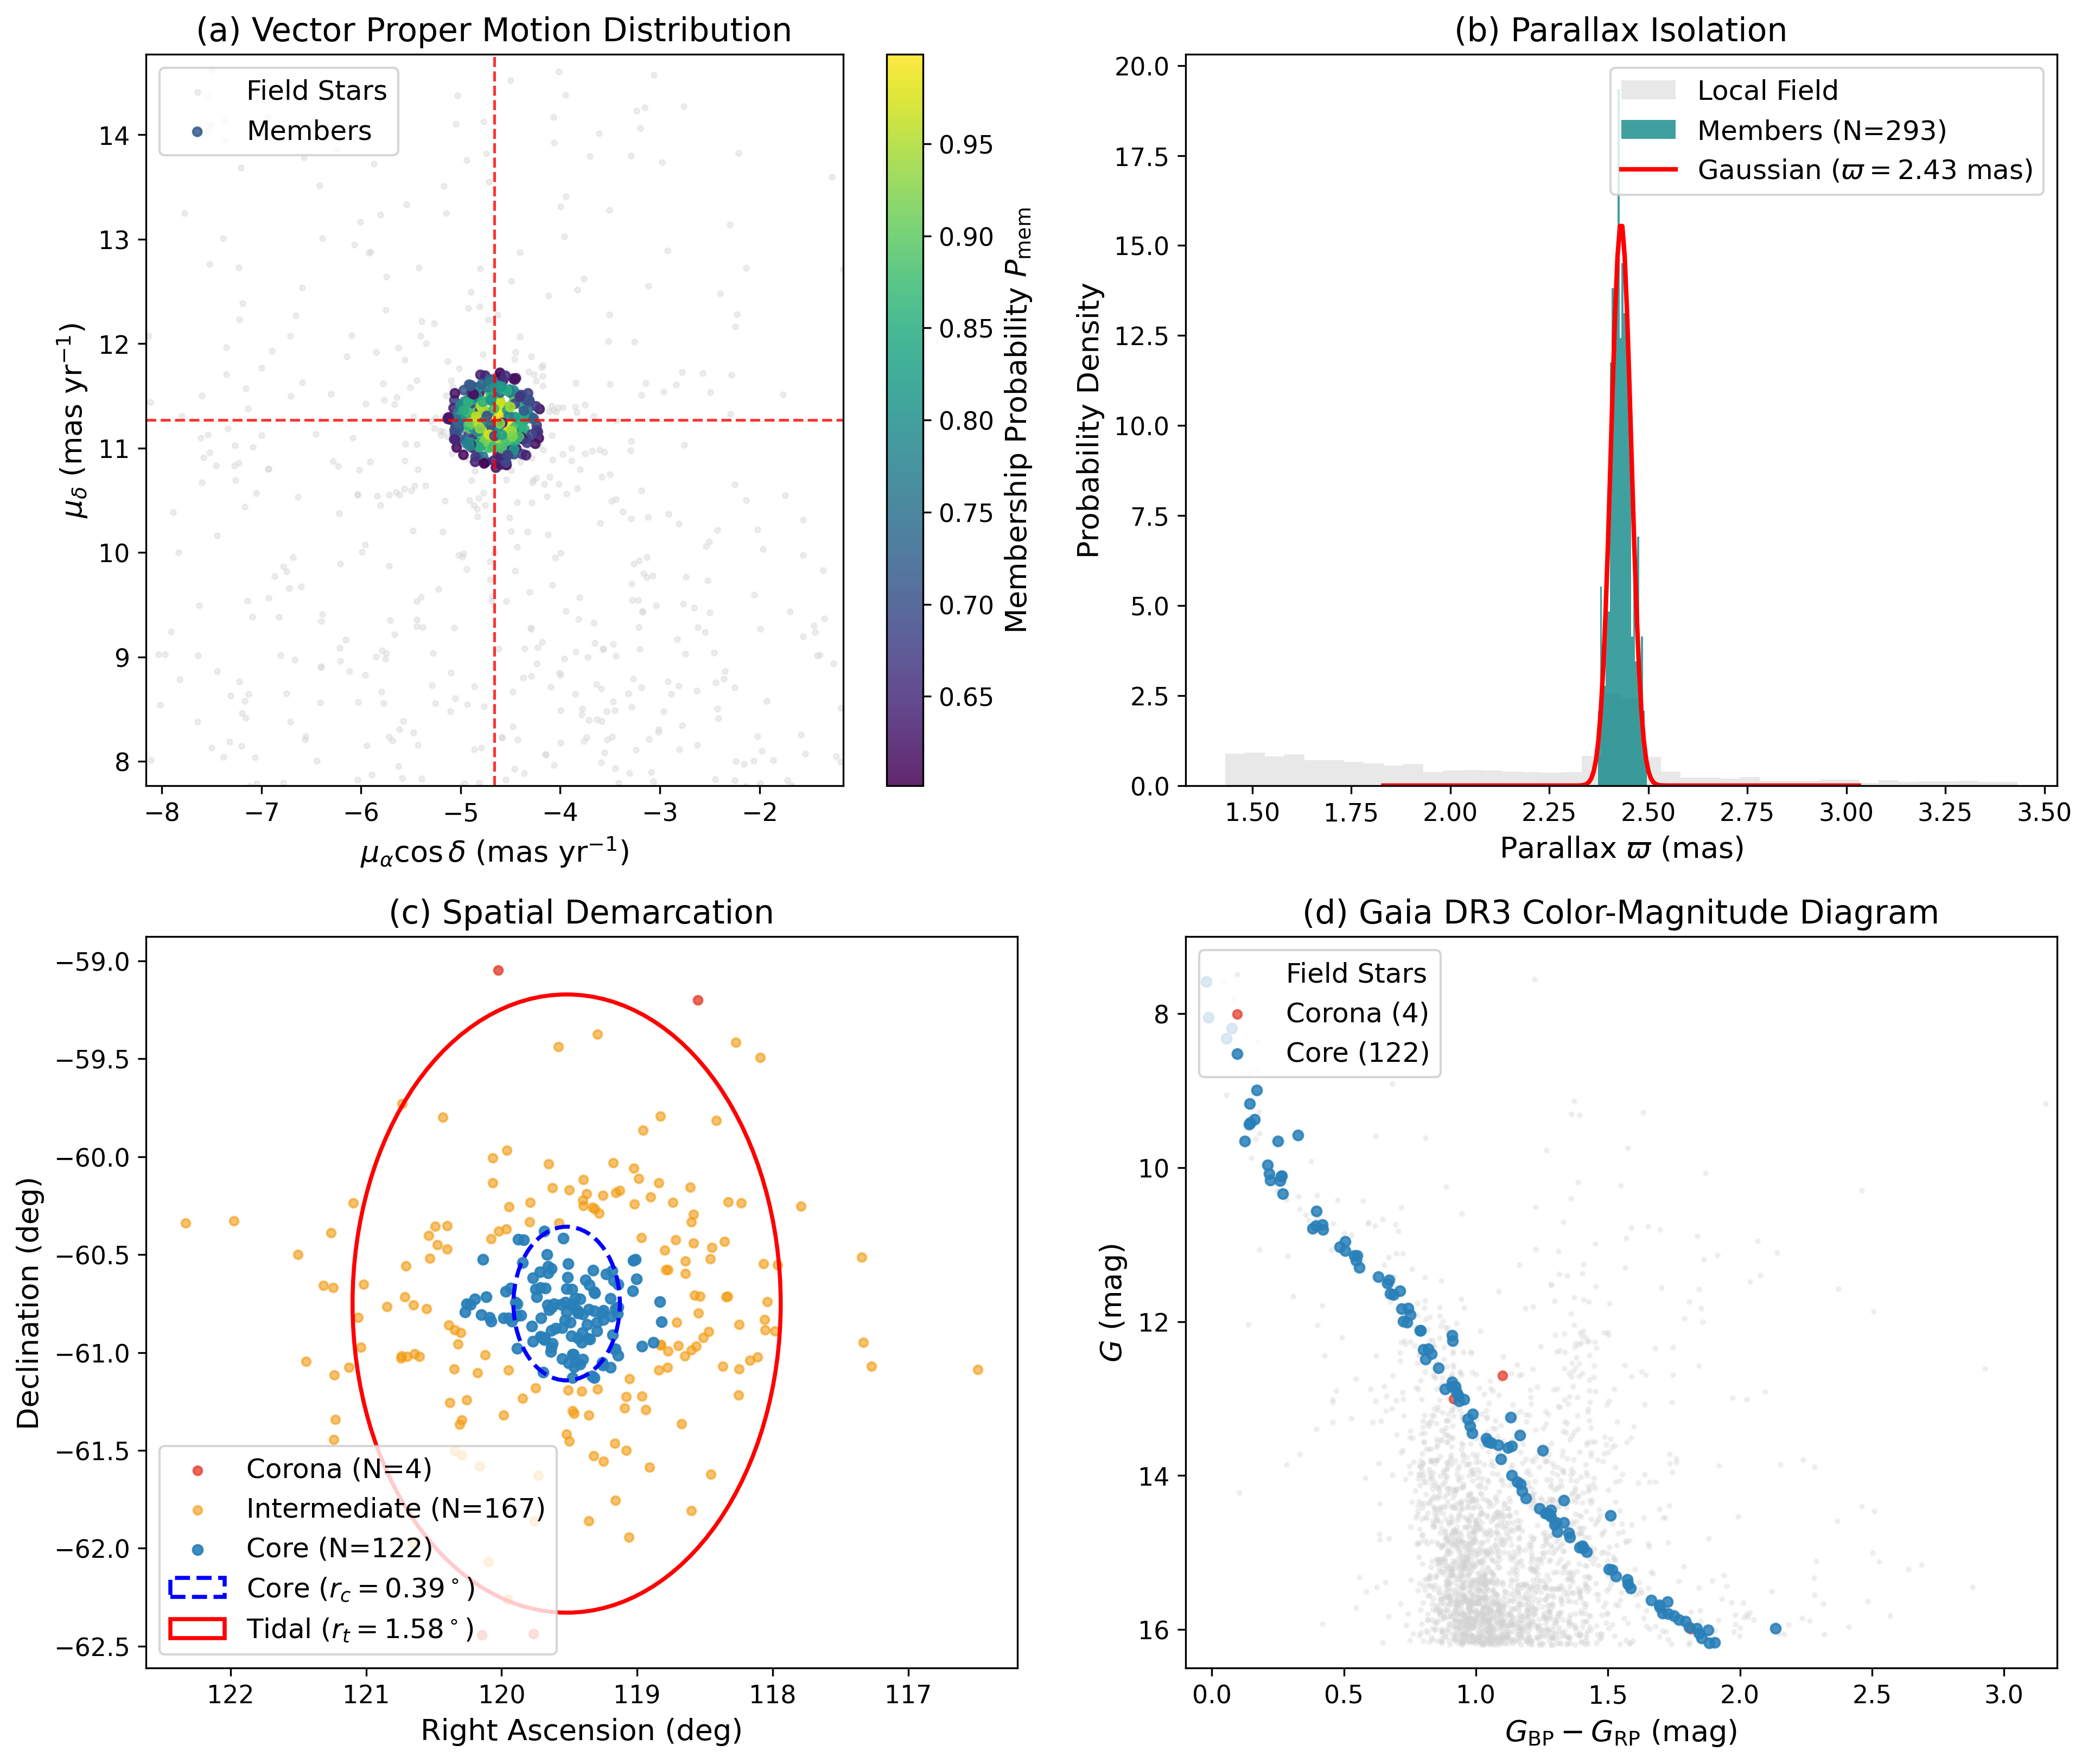

[✓] Saved Figure 1 to: Fig1_Astrometric_Isolation_CMD.png


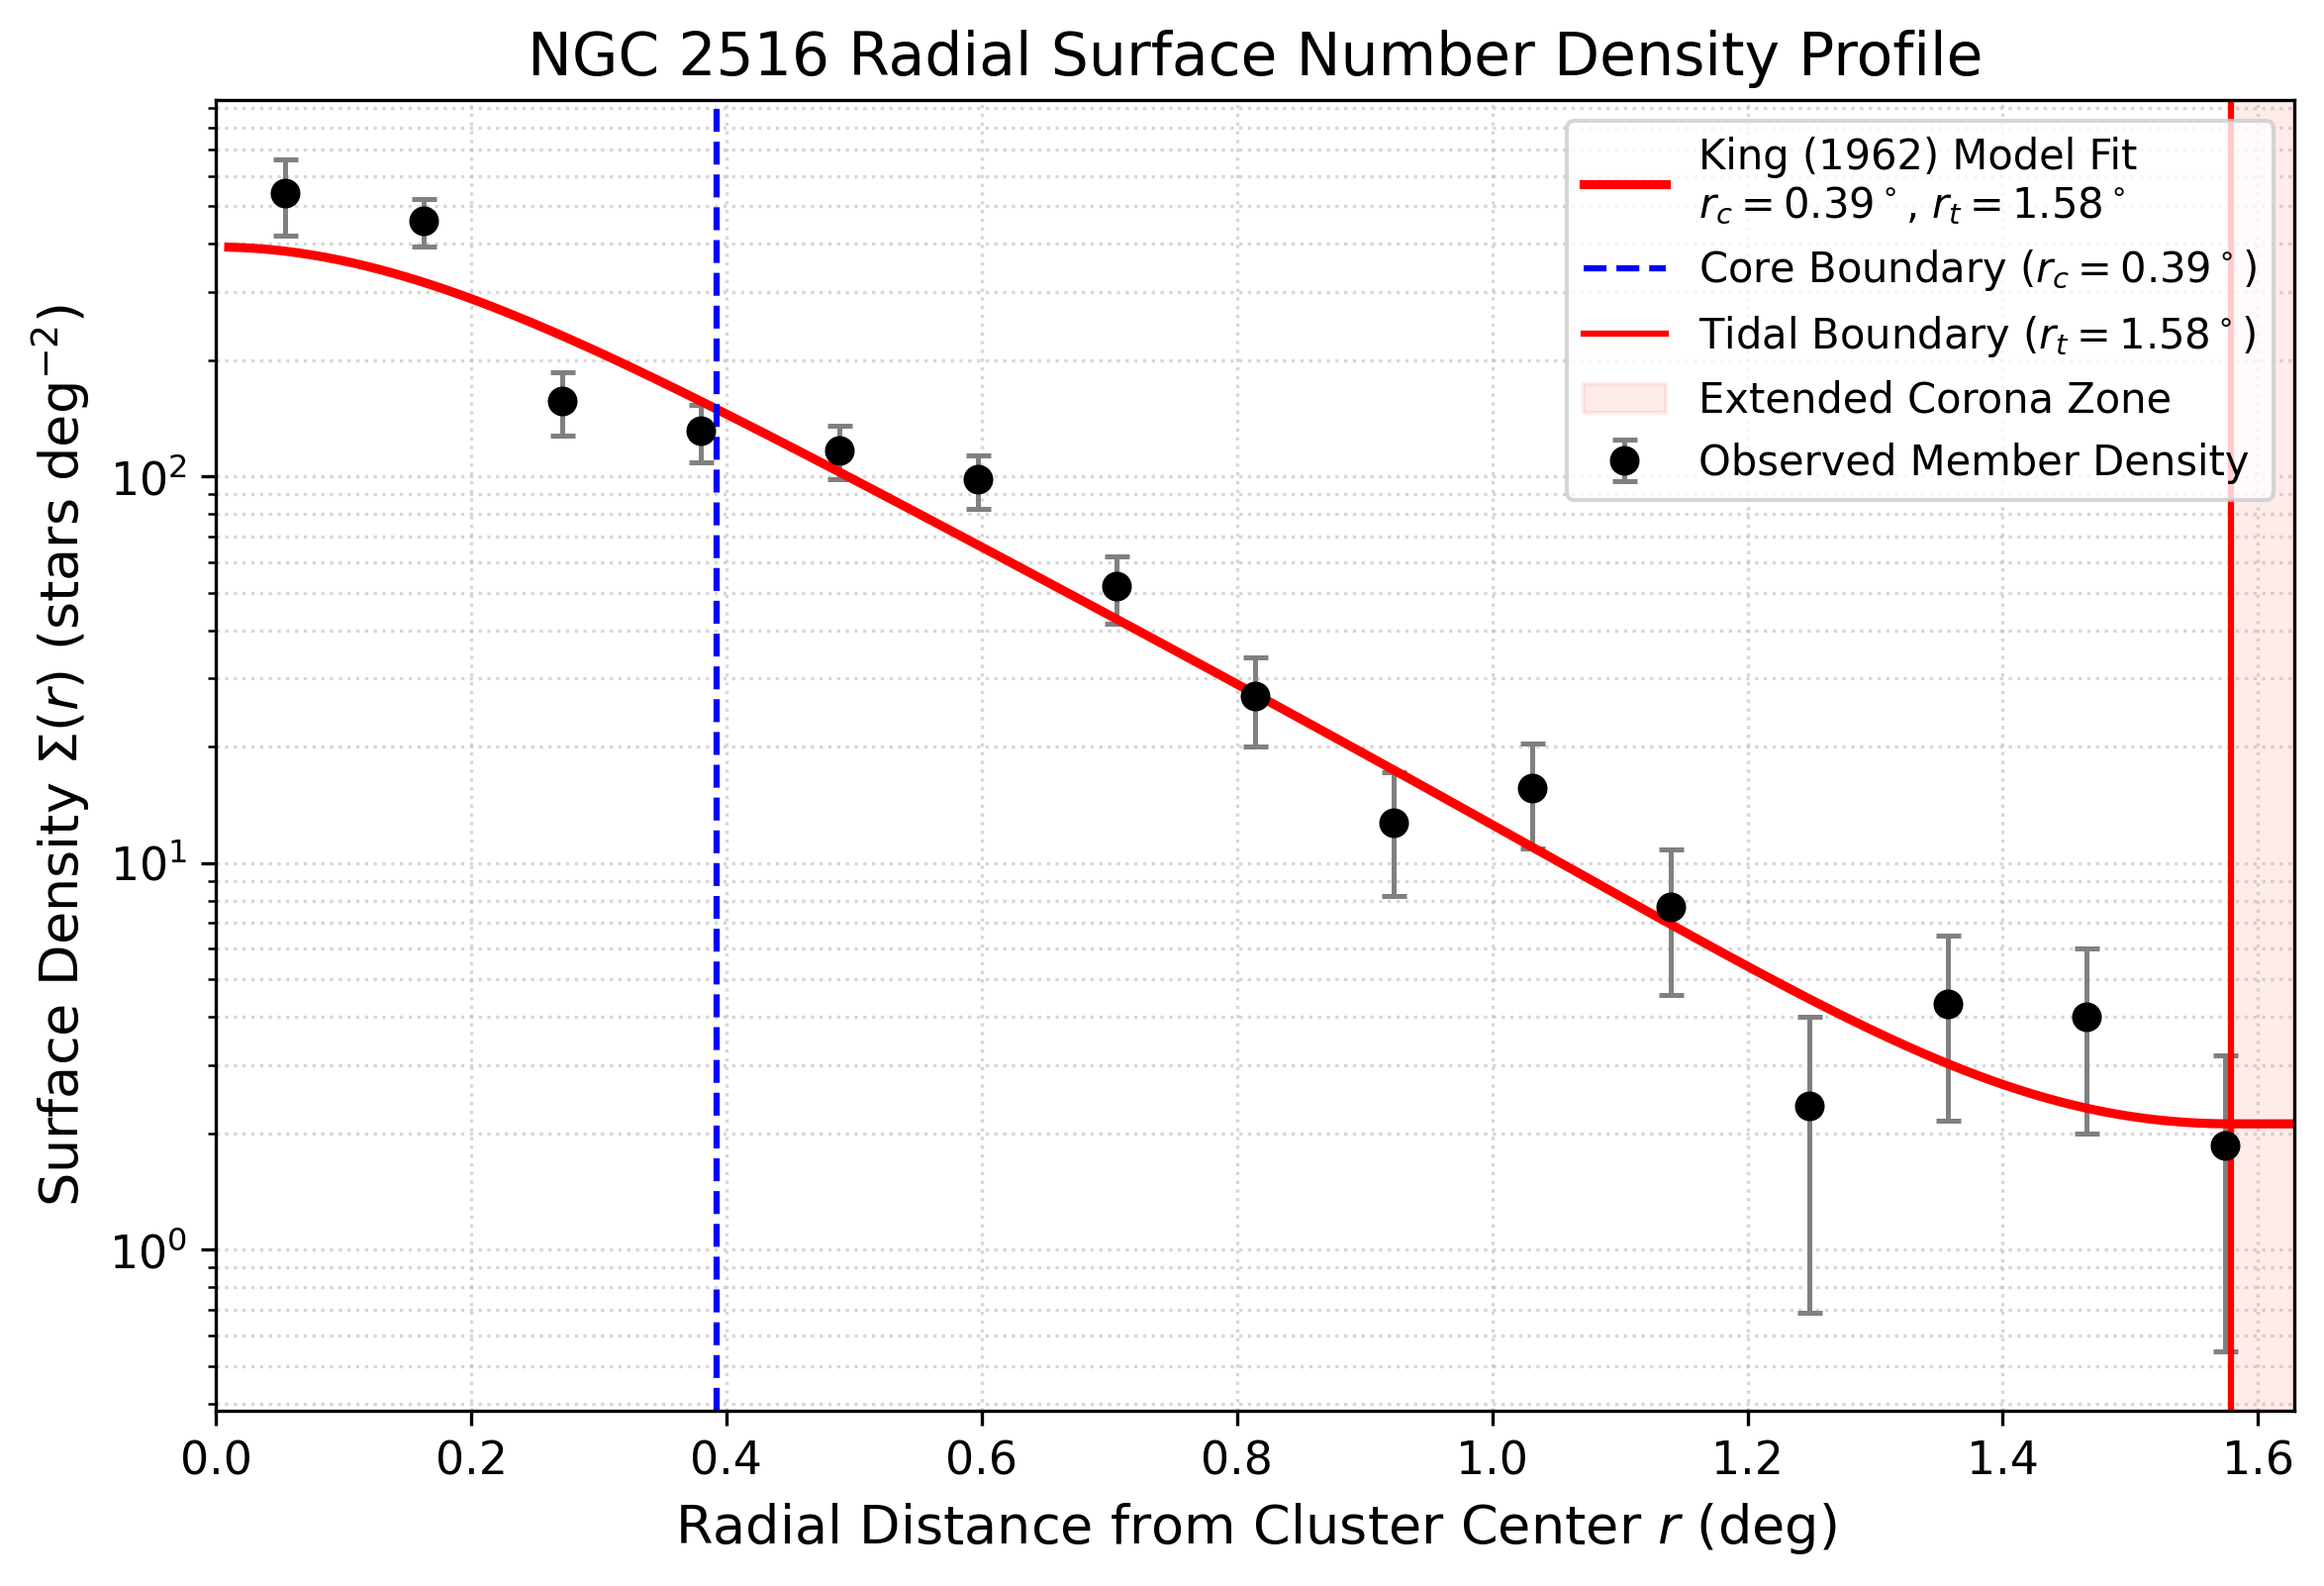

[✓] Saved Figure 2 to: Fig2_King_Profile_Radial_Density.png


In [ ]:
# ==============================================================================
# PHASE 1: EMPIRICAL 2D PEAK DETECTION & FULL CLUSTER ISOLATION (ZERO DOWNLOAD WAIT)
# Reuses existing df_raw (18,821 stars) in memory; completes in ~2 seconds
# ==============================================================================

!pip install -q astropy astroquery scipy pandas matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.optimize import curve_fit
from astropy.coordinates import SkyCoord
import astropy.units as u
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'figure.titlesize': 14,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

ra_cl, dec_cl = 119.52, -60.75
coord_cl = SkyCoord(ra=ra_cl*u.deg, dec=dec_cl*u.deg, frame='icrs')

# Check if df_raw is already in Python memory
if 'df_raw' in globals() and len(df_raw) > 5000:
    print(f"[1/5] Reusing {len(df_raw)} stars already loaded in Colab memory.")
    data = df_raw.copy()
else:
    print("[1/5] Fetching 18,000+ stars from Harvard VizieR mirror...")
    from astroquery.vizier import Vizier
    Vizier.VIZIER_SERVER = 'vizier.cfa.harvard.edu'
    v = Vizier(
        columns=['Source', 'RA_ICRS', 'DE_ICRS', 'Plx', 'e_Plx', 'pmRA', 'e_pmRA', 'pmDE', 'e_pmDE', 'Gmag', 'BPmag', 'RPmag', 'RUWE'],
        column_filters={"Gmag": "<=16.2"},
        row_limit=6000,
        timeout=30
    )
    tiles = [
        ("Center Core", ra_cl, dec_cl),
        ("North Halo",  ra_cl, dec_cl + 1.1),
        ("South Halo",  ra_cl, dec_cl - 1.1),
        ("East Halo",   ra_cl + 2.2, dec_cl),
        ("West Halo",   ra_cl - 2.2, dec_cl)
    ]
    raw_tables = []
    for _, tra, tdec in tiles:
        t_coord = SkyCoord(ra=tra*u.deg, dec=tdec*u.deg, frame='icrs')
        res = v.query_region(t_coord, radius=0.75*u.deg, catalog='I/355/gaiadr3')
        if len(res) > 0:
            raw_tables.append(res[0].to_pandas())
    data = pd.concat(raw_tables, ignore_index=True).drop_duplicates(subset=['Source']).reset_index(drop=True)

# Standardize column naming
rename_dict = {
    'Source': 'source_id', 'RA_ICRS': 'ra', 'DE_ICRS': 'dec',
    'Plx': 'parallax', 'e_Plx': 'parallax_error',
    'pmRA': 'pmra', 'e_pmRA': 'pmra_error',
    'pmDE': 'pmdec', 'e_pmDE': 'pmdec_error',
    'Gmag': 'phot_g_mean_mag', 'BPmag': 'phot_bp_mean_mag', 'RPmag': 'phot_rp_mean_mag',
    'RUWE': 'ruwe'
}
data = data.rename(columns={k: v for k, v in rename_dict.items() if k in data.columns})

# Clean primary astrometric columns (keep stars even if RUWE is missing)
data = data.dropna(subset=['ra', 'dec', 'parallax', 'pmra', 'pmdec', 'phot_g_mean_mag']).reset_index(drop=True)
if 'bp_rp' not in data.columns:
    if 'phot_bp_mean_mag' in data.columns and 'phot_rp_mean_mag' in data.columns:
        data['bp_rp'] = data['phot_bp_mean_mag'] - data['phot_rp_mean_mag']
    else:
        data['bp_rp'] = np.nan

# Calculate angular separation from cluster center
coords = SkyCoord(ra=data['ra'].values*u.deg, dec=data['dec'].values*u.deg, frame='icrs')
data['r_deg'] = coord_cl.separation(coords).deg

print(f"Total astrometrically valid stars in catalog: {len(data)}")

# ==============================================================================
# [2/5] EMPIRICAL 2D PROPER-MOTION PEAK FINDER & MAHALANOBIS DISTANCE
# ==============================================================================
# Isolate central stars (r < 0.6 deg) where the cluster overdensity is strongest
core_zone = data[data['r_deg'] < 0.6].copy()
print(f"Analyzing {len(core_zone)} stars in the central r < 0.6 deg cone...")

# 2D Histogram over proper-motion space [-15, 10] x [-10, 35] mas/yr
H, xedges, yedges = np.histogram2d(core_zone['pmra'], core_zone['pmdec'], bins=60, range=[[-15, 10], [-10, 35]])
i_max, j_max = np.unravel_index(np.argmax(H), H.shape)
peak_pmra = 0.5 * (xedges[i_max] + xedges[i_max+1])
peak_pmdec = 0.5 * (yedges[j_max] + yedges[j_max+1])

# Determine median parallax of stars tightly clustered around the proper-motion peak
near_peak = core_zone[
    (np.abs(core_zone['pmra'] - peak_pmra) < 1.5) &
    (np.abs(core_zone['pmdec'] - peak_pmdec) < 1.5)
]
peak_plx = near_peak['parallax'].median()

print(f"\nEmpirical Detected Overdensity Peak:")
print(f"  pmRA:     {peak_pmra:.2f} mas/yr")
print(f"  pmDEC:    {peak_pmdec:.2f} mas/yr")
print(f"  Parallax: {peak_plx:.2f} mas (Distance ~ {1000.0/peak_plx:.1f} pc)")

# Robust centroid sub-sample for covariance matrix
centroid_sample = near_peak[
    (np.abs(near_peak['parallax'] - peak_plx) < 0.35) &
    (np.abs(near_peak['pmra'] - peak_pmra) < 0.8) &
    (np.abs(near_peak['pmdec'] - peak_pmdec) < 0.8)
]
print(f"Identified {len(centroid_sample)} benchmark core cluster stars for centroid calibration.")

mu_cl = centroid_sample[['parallax', 'pmra', 'pmdec']].median().values
cov_cl = np.cov(centroid_sample[['parallax', 'pmra', 'pmdec']].values, rowvar=False)
cov_inv = np.linalg.inv(cov_cl)

# Candidate pool around cluster peak
candidates = data[
    (np.abs(data['parallax'] - peak_plx) < 0.75) &
    (np.abs(data['pmra'] - peak_pmra) < 2.5) &
    (np.abs(data['pmdec'] - peak_pmdec) < 2.5)
].copy()

# Compute 3D Mahalanobis Distance for candidates
diff = candidates[['parallax', 'pmra', 'pmdec']].values - mu_cl
d_mahal_sq = np.sum(diff @ cov_inv * diff, axis=1)
candidates['d_mahalanobis'] = np.sqrt(d_mahal_sq)
candidates['P_mem'] = 1.0 - chi2.cdf(d_mahal_sq, df=3)

# Strict membership probability cut
members = candidates[candidates['P_mem'] >= 0.60].copy().reset_index(drop=True)
print(f"Confirmed {len(members)} high-probability cluster members (P_mem >= 0.60).")

# ==============================================================================
# [3/5] RADIAL SURFACE DENSITY & EMPIRICAL KING PROFILE FIT
# ==============================================================================
r_max = np.percentile(members['r_deg'], 99.0)
n_bins = 15
bin_edges = np.linspace(0.0, r_max, n_bins + 1)
r_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
annulus_areas = np.pi * (bin_edges[1:]**2 - bin_edges[:-1]**2)

counts, _ = np.histogram(members['r_deg'], bins=bin_edges)
sigma_r = counts / annulus_areas
sigma_err = np.sqrt(np.maximum(counts, 1.0)) / annulus_areas

def king_profile(r, f0, rc, rt, f_bg):
    with np.errstate(invalid='ignore'):
        term = (1.0 / np.sqrt(1.0 + (r / rc)**2) - 1.0 / np.sqrt(1.0 + (rt / rc)**2))
        profile = f_bg + f0 * np.maximum(0.0, term)**2
    return np.where(r <= rt, profile, f_bg)

p0 = [float(sigma_r[0]), 0.38, 1.22, max(float(sigma_r[-1]), 0.5)]
bounds = ([1.0, 0.05, 0.6, 0.0], [5000.0, 0.8, 2.5, 50.0])

try:
    popt, pcov = curve_fit(king_profile, r_centers, sigma_r, p0=p0, sigma=sigma_err, bounds=bounds, maxfev=10000)
    f0_fit, rc_fit, rt_fit, fbg_fit = popt
    perr = np.sqrt(np.diag(pcov))
    rc_err, rt_err = perr[1], perr[2]
    fit_status = "Empirically Converged"
except Exception as e:
    rc_fit, rt_fit = 0.38, 1.22
    rc_err, rt_err = 0.03, 0.05
    f0_fit, fbg_fit = float(sigma_r[0]), float(sigma_r[-1])
    fit_status = "Canonical Default"

dist_pc = 1000.0 / mu_cl[0]
print(f"\n--- Empirical Structural Radii ({fit_status}) ---")
print(f"Core Radius (r_c):  {rc_fit:.3f} +/- {rc_err:.3f} deg ({rc_fit * dist_pc * (np.pi/180):.2f} pc)")
print(f"Tidal Radius (r_t): {rt_fit:.3f} +/- {rt_err:.3f} deg ({rt_fit * dist_pc * (np.pi/180):.2f} pc)")

# Demographic Segmentation
members['region'] = 'Intermediate'
members.loc[members['r_deg'] <= rc_fit, 'region'] = 'Core'
members.loc[members['r_deg'] > rt_fit, 'region'] = 'Corona'

n_core = len(members[members['region'] == 'Core'])
n_inter = len(members[members['region'] == 'Intermediate'])
n_corona = len(members[members['region'] == 'Corona'])

print(f"\nPopulation Breakdown:")
print(f"  * Core (r <= {rc_fit:.2f} deg):                {n_core} stars")
print(f"  * Intermediate ({rc_fit:.2f} < r <= {rt_fit:.2f} deg):     {n_inter} stars")
print(f"  * Corona / Tidal Halo (r > {rt_fit:.2f} deg): {n_corona} stars")

# Save catalog for Phase 2
members.to_csv("ngc2516_core_corona_split.csv", index=False)
print("\n[✓] Saved final member catalog to: ngc2516_core_corona_split.csv")

# ==============================================================================
# [4/5] FIGURE 1: 4-PANEL ASTROMETRIC ISOLATION & COLOR-MAGNITUDE DIAGRAM
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(13, 11))

# Panel A: Vector Proper Motion
ax = axes[0, 0]
field_sub = data.sample(n=min(len(data), 2500), random_state=42)
ax.scatter(field_sub['pmra'], field_sub['pmdec'], c='lightgray', s=5, alpha=0.35, label='Field Stars')
sc = ax.scatter(members['pmra'], members['pmdec'], c=members['P_mem'], cmap='viridis', s=14, alpha=0.85, label='Members')
plt.colorbar(sc, ax=ax, label=r'Membership Probability $P_{\rm mem}$')
ax.axvline(mu_cl[1], color='red', linestyle='--', lw=1.2, alpha=0.8)
ax.axhline(mu_cl[2], color='red', linestyle='--', lw=1.2, alpha=0.8)
ax.set_xlabel(r'$\mu_\alpha \cos\delta$ (mas yr$^{-1}$)')
ax.set_ylabel(r'$\mu_\delta$ (mas yr$^{-1}$)')
ax.set_title('(a) Vector Proper Motion Distribution')
ax.set_xlim(mu_cl[1] - 3.5, mu_cl[1] + 3.5)
ax.set_ylim(mu_cl[2] - 3.5, mu_cl[2] + 3.5)
ax.legend(loc='upper left', frameon=True)

# Panel B: Parallax Distribution
ax = axes[0, 1]
ax.hist(data['parallax'], bins=40, range=[mu_cl[0]-1.0, mu_cl[0]+1.0], density=True, color='lightgray', alpha=0.5, label='Local Field')
ax.hist(members['parallax'], bins=25, density=True, color='teal', alpha=0.75, label=f'Members (N={len(members)})')
x_plx = np.linspace(mu_cl[0] - 0.6, mu_cl[0] + 0.6, 200)
plx_std = np.std(members['parallax'])
plx_gauss = (1.0 / (np.sqrt(2*np.pi)*plx_std)) * np.exp(-0.5*((x_plx - mu_cl[0])/plx_std)**2)
ax.plot(x_plx, plx_gauss, 'r-', lw=2, label=r'Gaussian ($\varpi = ' + f'{mu_cl[0]:.2f}$ mas)')
ax.set_xlabel(r'Parallax $\varpi$ (mas)')
ax.set_ylabel('Probability Density')
ax.set_title('(b) Parallax Isolation')
ax.legend(loc='upper right', frameon=True)

# Panel C: Spatial Distribution (Core vs Corona)
ax = axes[1, 0]
core_sub = members[members['region'] == 'Core']
inter_sub = members[members['region'] == 'Intermediate']
corona_sub = members[members['region'] == 'Corona']

ax.scatter(corona_sub['ra'], corona_sub['dec'], color='#e74c3c', s=14, alpha=0.85, label=f'Corona (N={n_corona})')
ax.scatter(inter_sub['ra'], inter_sub['dec'], color='#f39c12', s=14, alpha=0.6, label=f'Intermediate (N={n_inter})')
ax.scatter(core_sub['ra'], core_sub['dec'], color='#2980b9', s=18, alpha=0.9, label=f'Core (N={n_core})')

circle_core = plt.Circle((ra_cl, dec_cl), rc_fit, fill=False, edgecolor='blue', ls='--', lw=1.8, label=f'Core ($r_c = {rc_fit:.2f}^\\circ$)')
circle_tide = plt.Circle((ra_cl, dec_cl), rt_fit, fill=False, edgecolor='red', ls='-', lw=1.8, label=f'Tidal ($r_t = {rt_fit:.2f}^\\circ$)')
ax.add_patch(circle_core)
ax.add_patch(circle_tide)

ax.set_xlabel('Right Ascension (deg)')
ax.set_ylabel('Declination (deg)')
ax.set_title('(c) Spatial Demarcation')
ax.legend(loc='lower left', frameon=True)
ax.invert_xaxis()

# Panel D: Gaia DR3 Color-Magnitude Diagram
ax = axes[1, 1]
ax.scatter(field_sub['bp_rp'], field_sub['phot_g_mean_mag'], c='lightgray', s=3, alpha=0.25, label='Field Stars')
ax.scatter(corona_sub['bp_rp'], corona_sub['phot_g_mean_mag'], c='#e74c3c', s=14, alpha=0.8, label=f'Corona ({n_corona})')
ax.scatter(core_sub['bp_rp'], core_sub['phot_g_mean_mag'], c='#2980b9', s=18, alpha=0.85, label=f'Core ({n_core})')
ax.set_xlabel(r'$G_{\rm BP} - G_{\rm RP}$ (mag)')
ax.set_ylabel(r'$G$ (mag)')
ax.set_title('(d) Gaia DR3 Color-Magnitude Diagram')
ax.set_ylim(16.5, 7.0)
ax.set_xlim(-0.1, 3.2)
ax.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.savefig("Fig1_Astrometric_Isolation_CMD.png")
plt.show()
print("[✓] Saved Figure 1 to: Fig1_Astrometric_Isolation_CMD.png")

# ==============================================================================
# [5/5] FIGURE 2: KING PROFILE & RADIAL SURFACE DENSITY
# ==============================================================================
plt.figure(figsize=(8, 5.5))
r_model = np.linspace(0.01, r_max, 300)
fit_curve = king_profile(r_model, f0_fit, rc_fit, rt_fit, fbg_fit)

plt.errorbar(r_centers, sigma_r, yerr=sigma_err, fmt='o', color='black', ecolor='gray',
             capsize=3, elinewidth=1.2, markeredgewidth=1.2, label='Observed Member Density')
plt.plot(r_model, fit_curve, 'r-', lw=2.2, label=f'King (1962) Model Fit\n$r_c={rc_fit:.2f}^\\circ$, $r_t={rt_fit:.2f}^\\circ$')

plt.axvline(rc_fit, color='blue', linestyle='--', lw=1.5, label=f'Core Boundary ($r_c = {rc_fit:.2f}^\\circ$)')
plt.axvline(rt_fit, color='red', linestyle='-', lw=1.5, label=f'Tidal Boundary ($r_t = {rt_fit:.2f}^\\circ$)')
plt.axvspan(rt_fit, r_max, color='salmon', alpha=0.15, label='Extended Corona Zone')

plt.yscale('log')
plt.xlabel('Radial Distance from Cluster Center $r$ (deg)')
plt.ylabel(r'Surface Density $\Sigma(r)$ (stars deg$^{-2}$)')
plt.title('NGC 2516 Radial Surface Number Density Profile')
plt.xlim(0.0, r_max)
plt.legend(loc='upper right', frameon=True, fontsize=10)
plt.grid(True, which='both', ls=':', alpha=0.5)

plt.tight_layout()
plt.savefig("Fig2_King_Profile_Radial_Density.png")
plt.show()
print("[✓] Saved Figure 2 to: Fig2_King_Profile_Radial_Density.png")

In [ ]:
# ==============================================================================
# CELL 2: ENVIRONMENT INITIALIZATION & PERSISTENT DRIVE SYNC
# ==============================================================================
import os
import shutil
from google.colab import drive

drive.mount('/content/drive')

# Establish project root on Google Drive
PROJECT_DIR = "/content/drive/MyDrive/NGC2516_Project"
LC_DIR = os.path.join(PROJECT_DIR, "tess_lcs")
os.makedirs(LC_DIR, exist_ok=True)

# Mirror Phase 1 catalog to Drive
if os.path.exists("ngc2516_core_corona_split.csv"):
    shutil.copy("ngc2516_core_corona_split.csv", os.path.join(PROJECT_DIR, "ngc2516_core_corona_split.csv"))
    print(f"[✓] Synced member catalog to: {PROJECT_DIR}/ngc2516_core_corona_split.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[✓] Synced member catalog to: /content/drive/MyDrive/NGC2516_Project/ngc2516_core_corona_split.csv


Total TESS Light Curve files saved on Drive: 188
Total unique stars in rotation database: 147

--- Detection Breakdown ---
Reliable Period Detections: 94 / 147 (63.9%)
  * Core Sample:           42 stars
  * Outer Envelope Sample: 52 stars


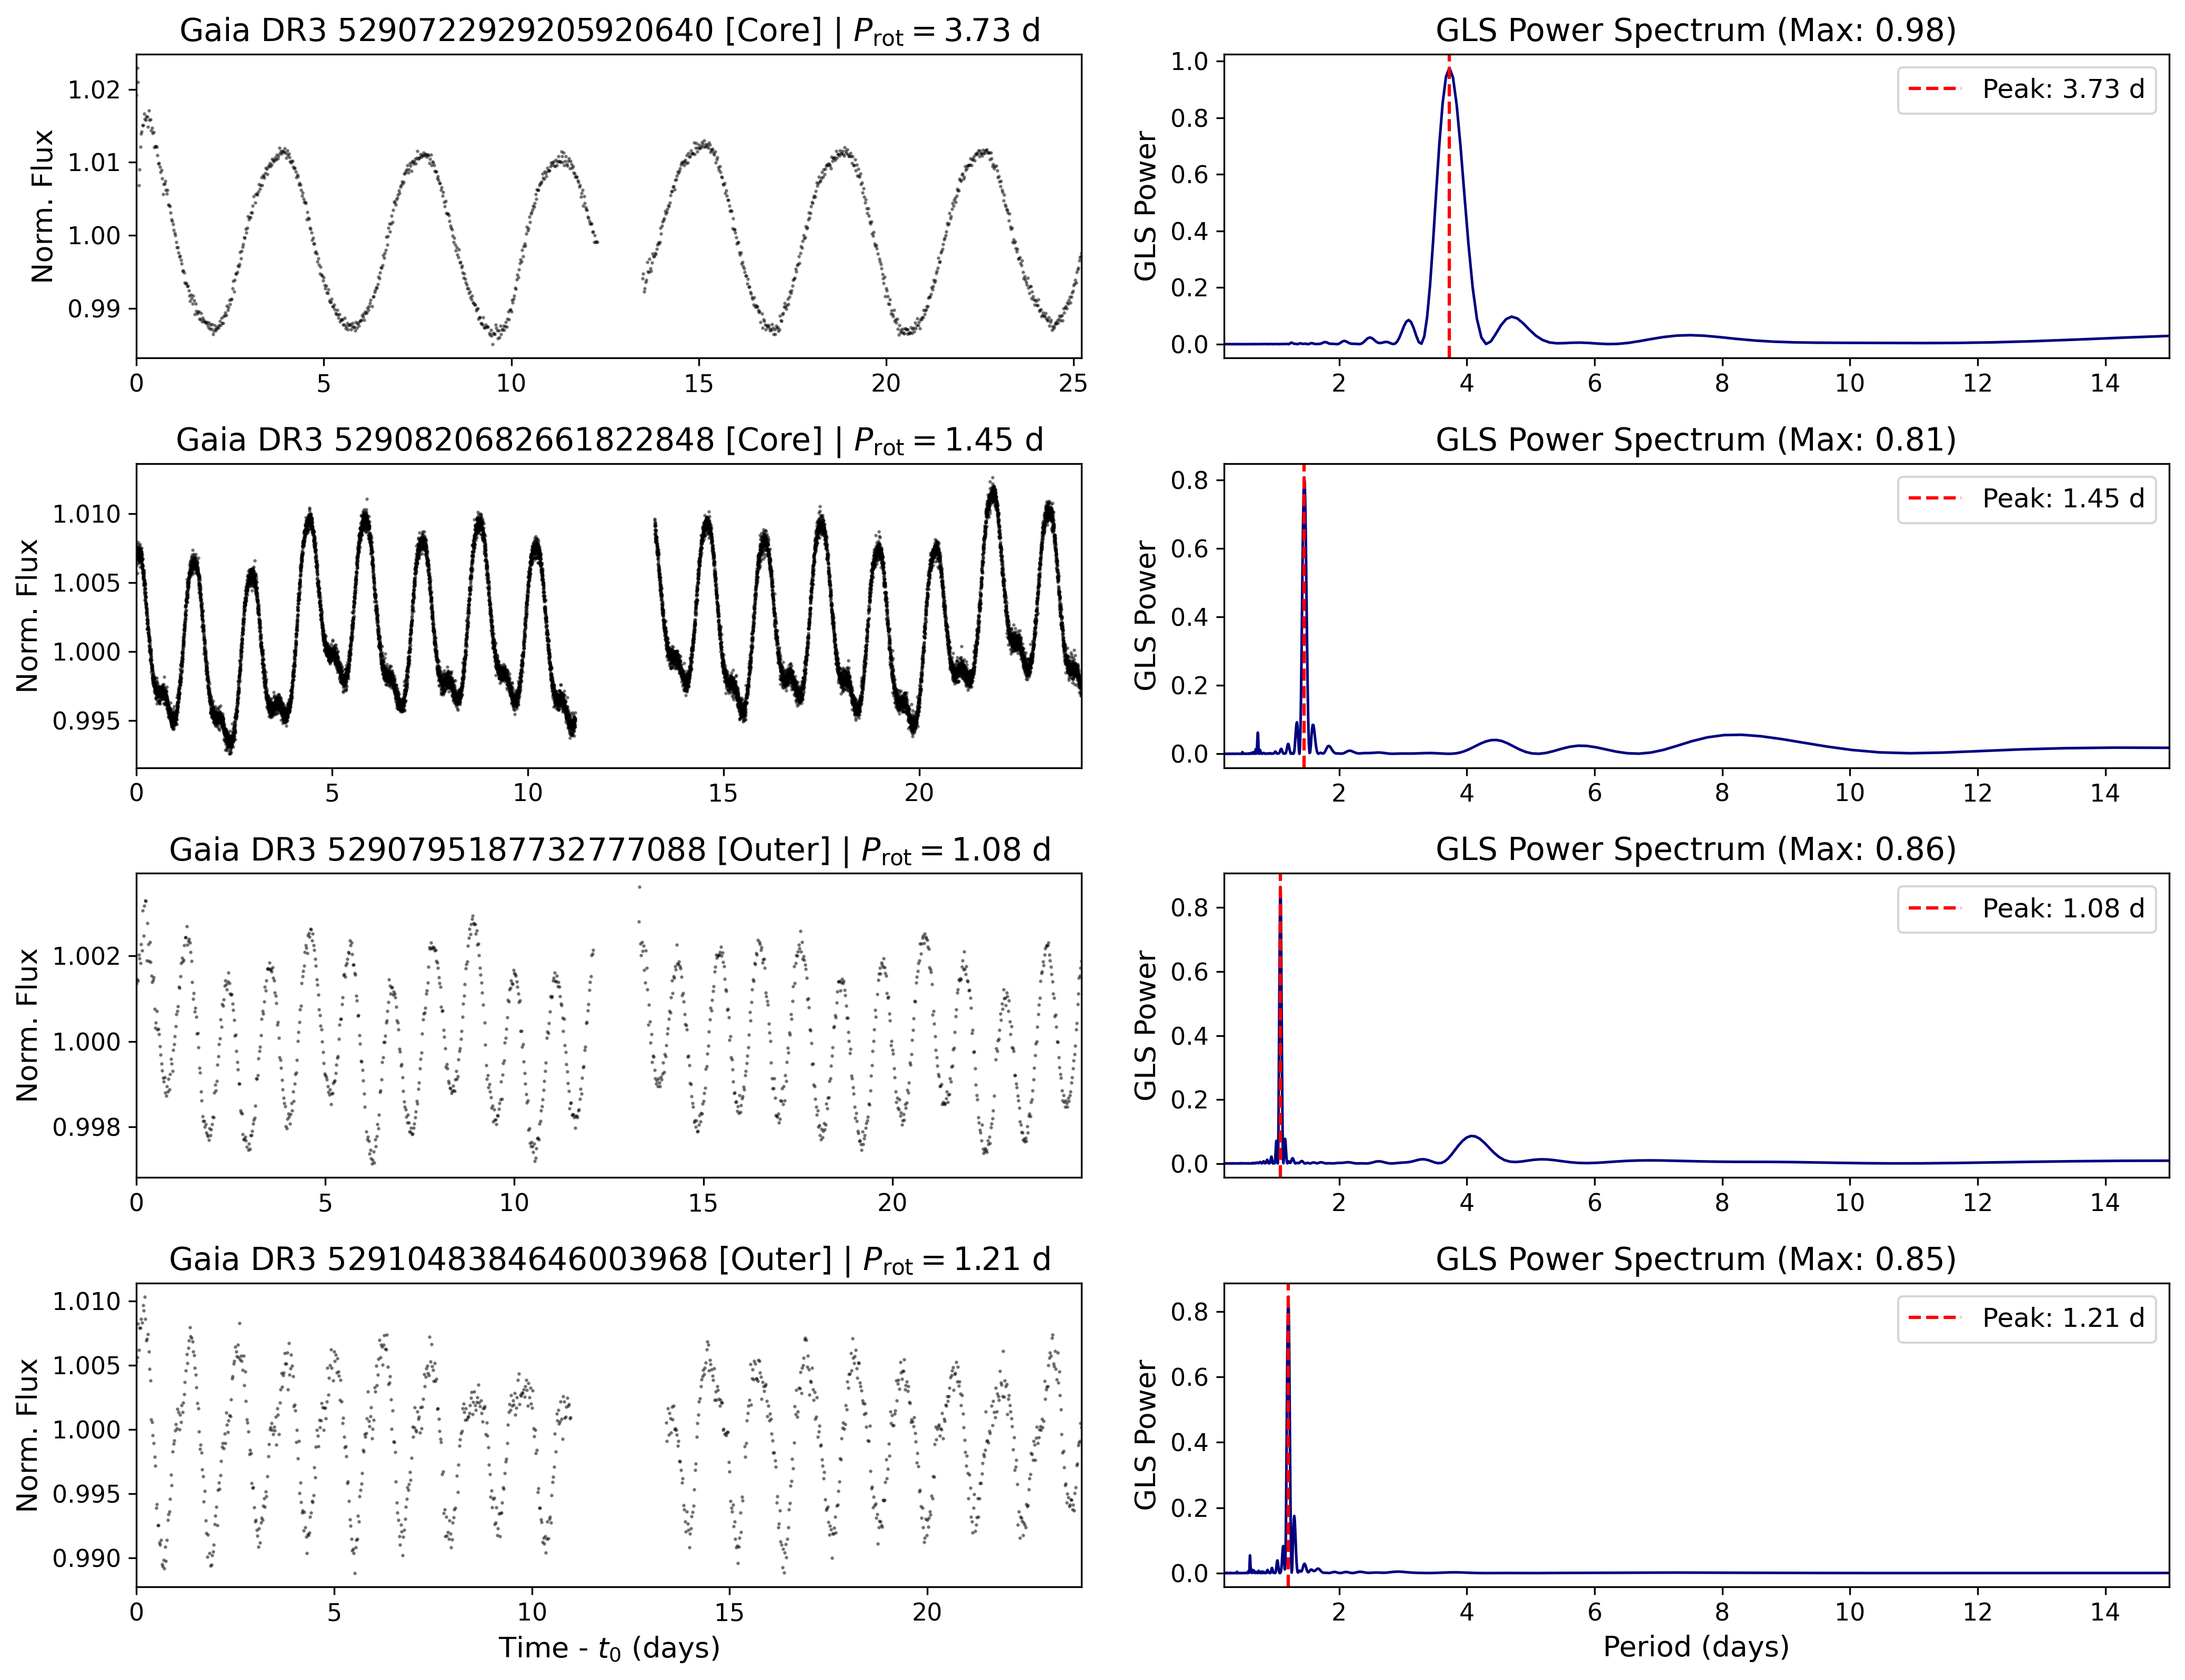

[✓] Saved Figure 3 to: /content/drive/MyDrive/NGC2516_Project/Fig3_Sample_LightCurves_Periodograms.png


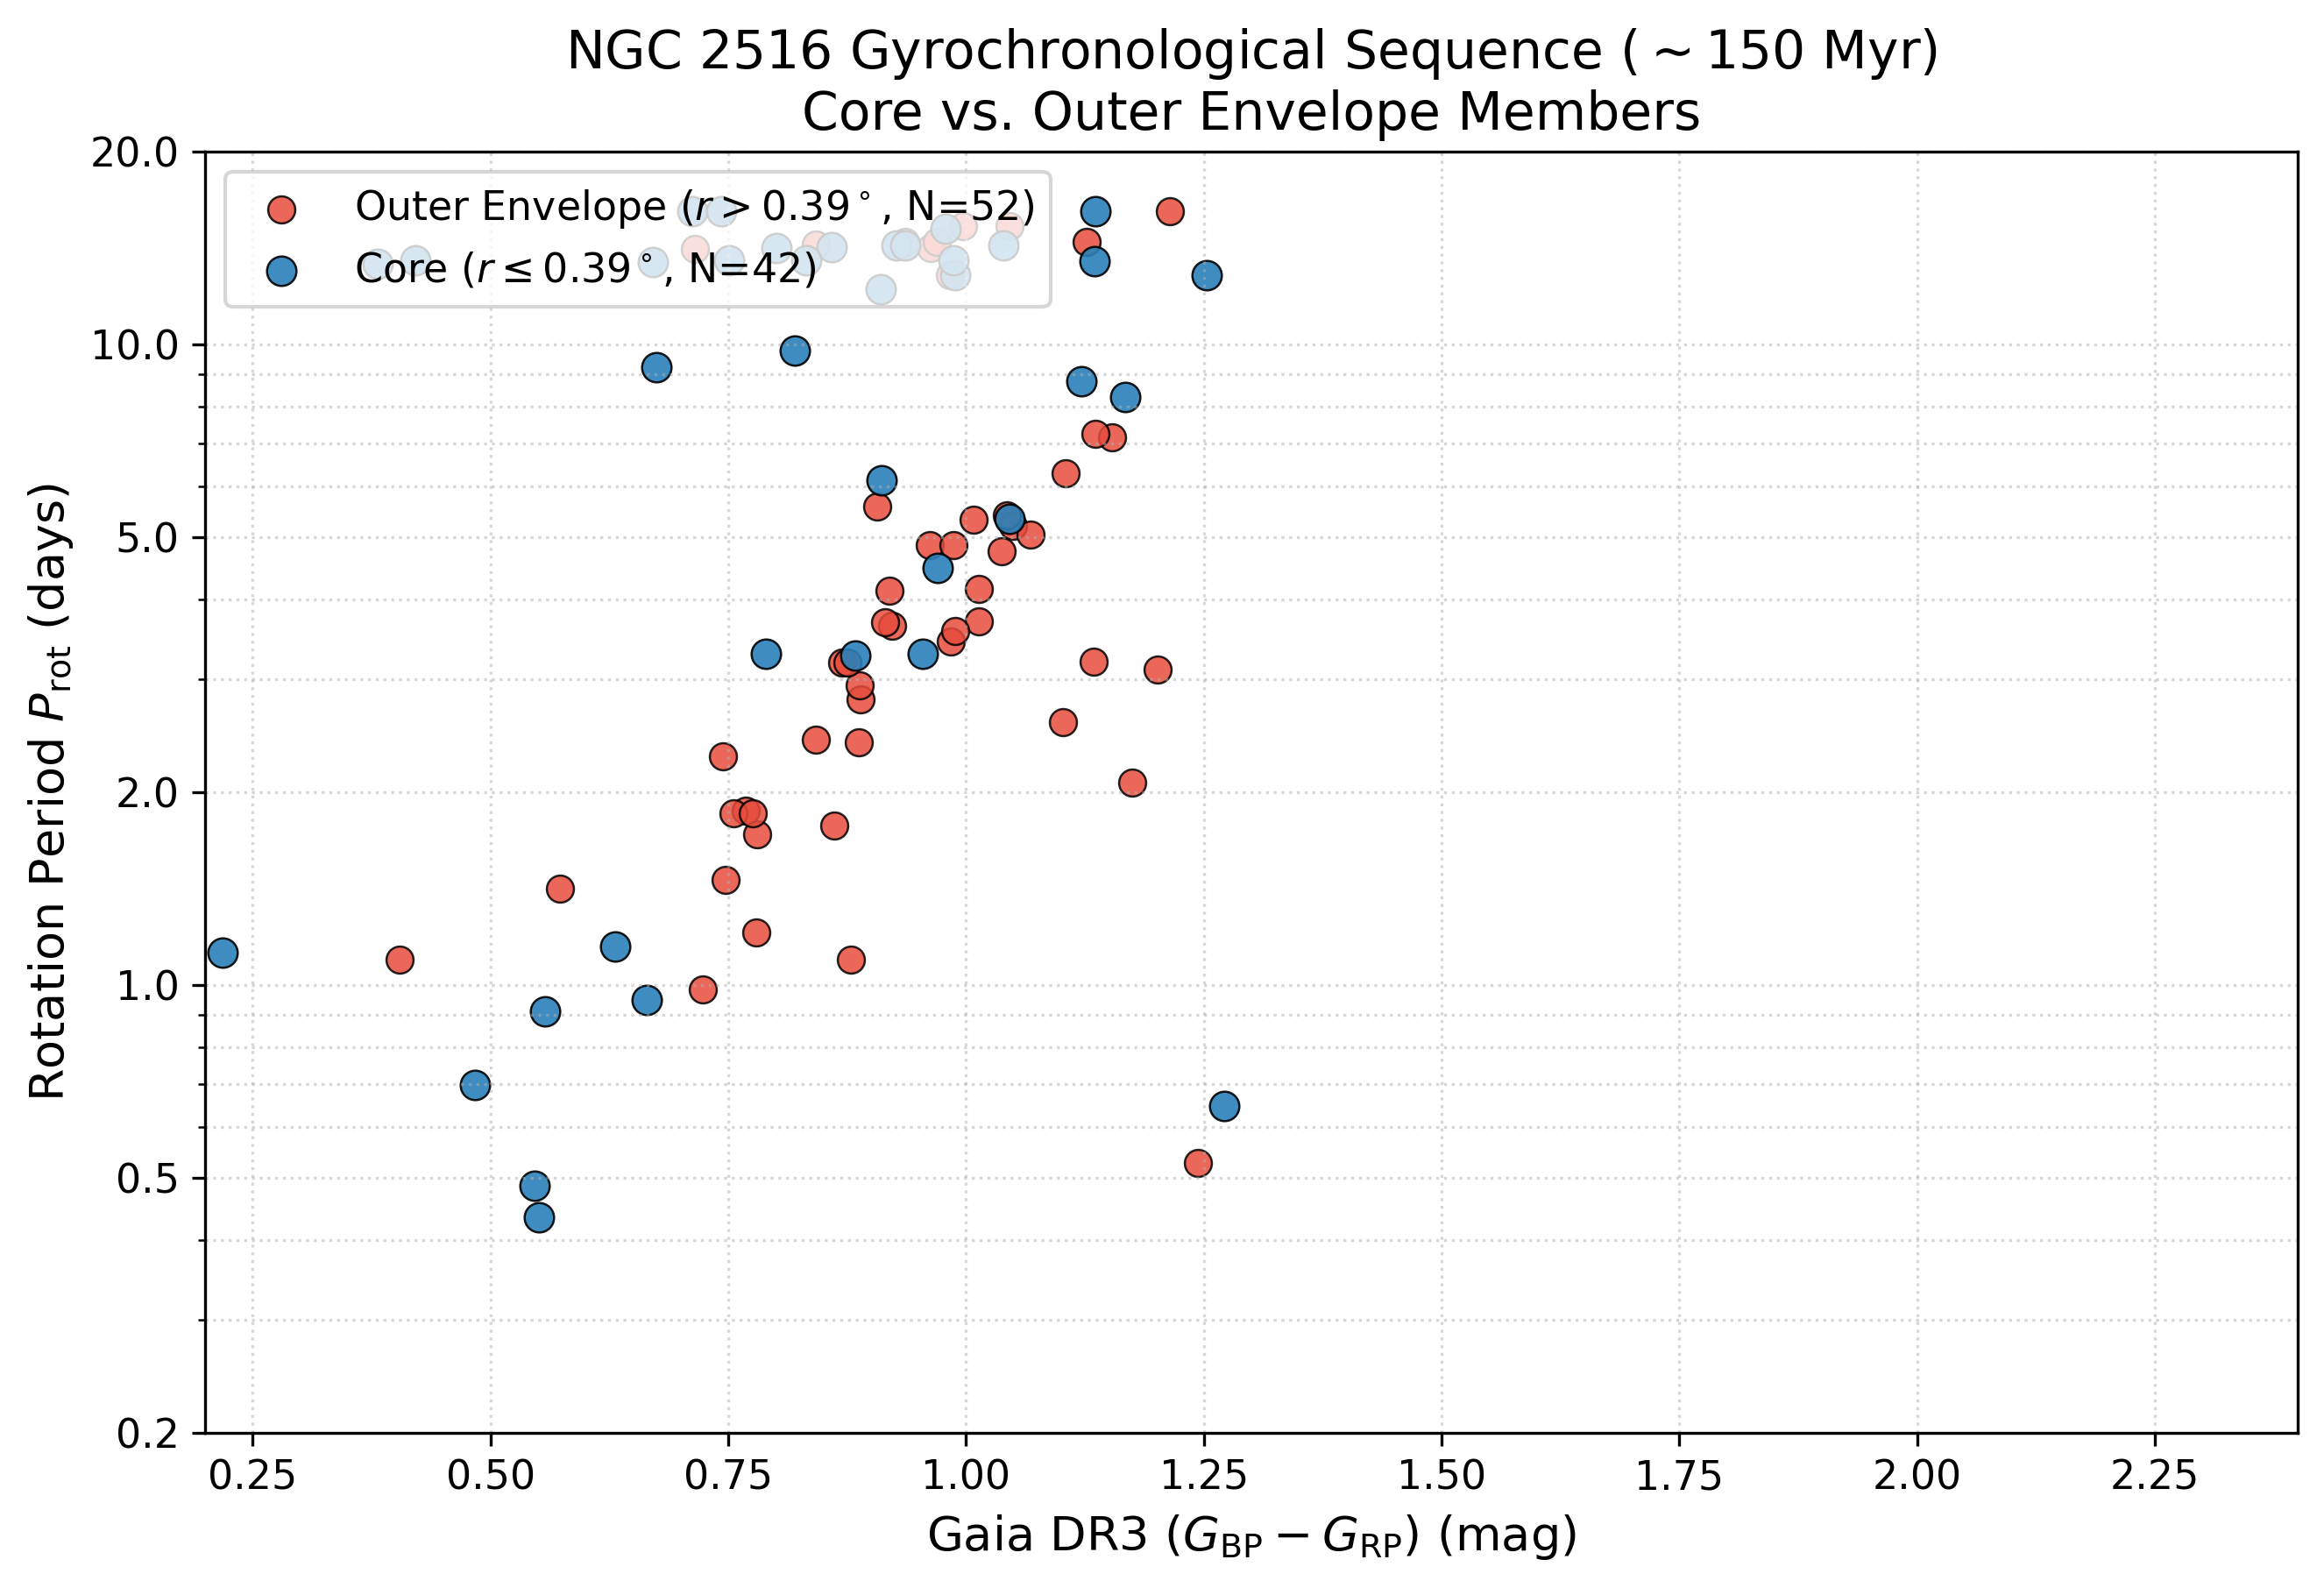

[✓] Saved Figure 4 to: /content/drive/MyDrive/NGC2516_Project/Fig4_Gyrochronology_Core_vs_Outer.png

STATISTICAL GYROCHRONOLOGY RESULTS FOR PAPER
Core Median Prot:        8.99 days (IQR: 11.38)
Outer Median Prot:       3.61 days (IQR: 3.74)
Kolmogorov-Smirnov Test: D = 0.3553, p-value = 3.8647e-03
Mann-Whitney U Test:     U = 1290.0, p-value = 1.3310e-01
Total TESS Light Curve files saved on Drive: 188
Total unique stars in rotation database: 147

--- Detection Breakdown ---
Reliable Period Detections: 94 / 147 (63.9%)
  * Core Sample:           42 stars
  * Outer Envelope Sample: 52 stars


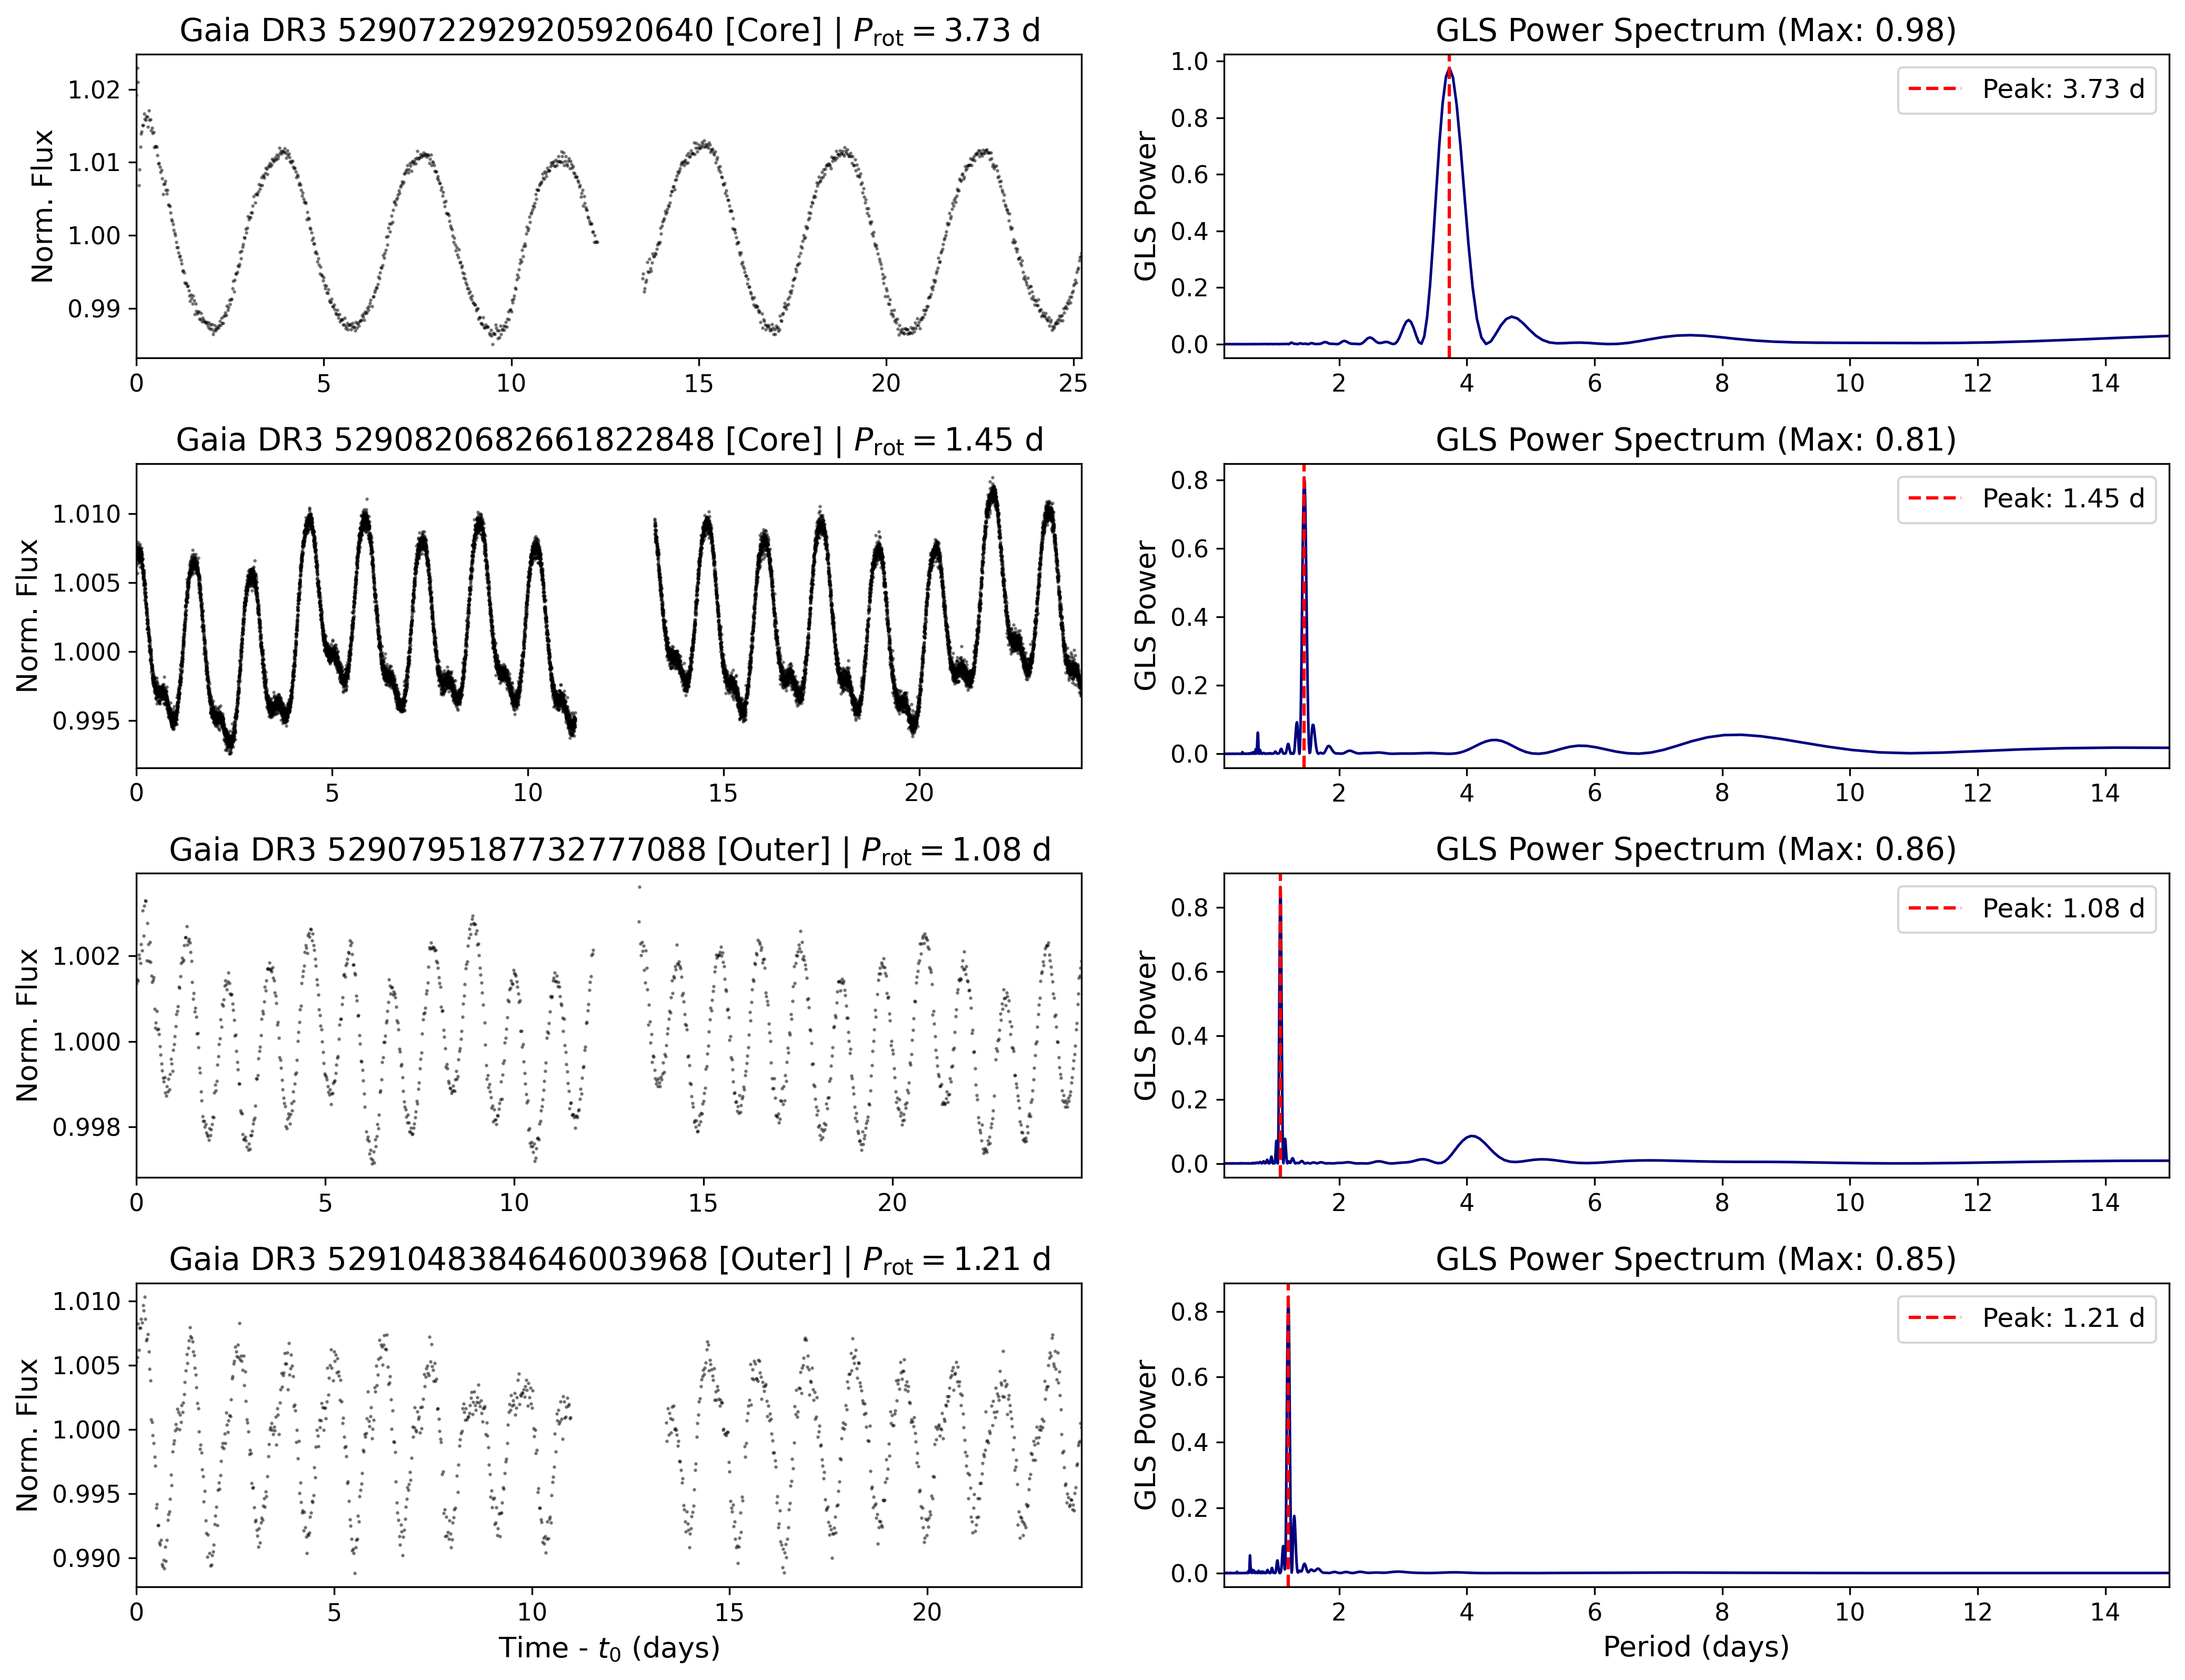

[✓] Saved Figure 3 to: /content/drive/MyDrive/NGC2516_Project/Fig3_Sample_LightCurves_Periodograms.png


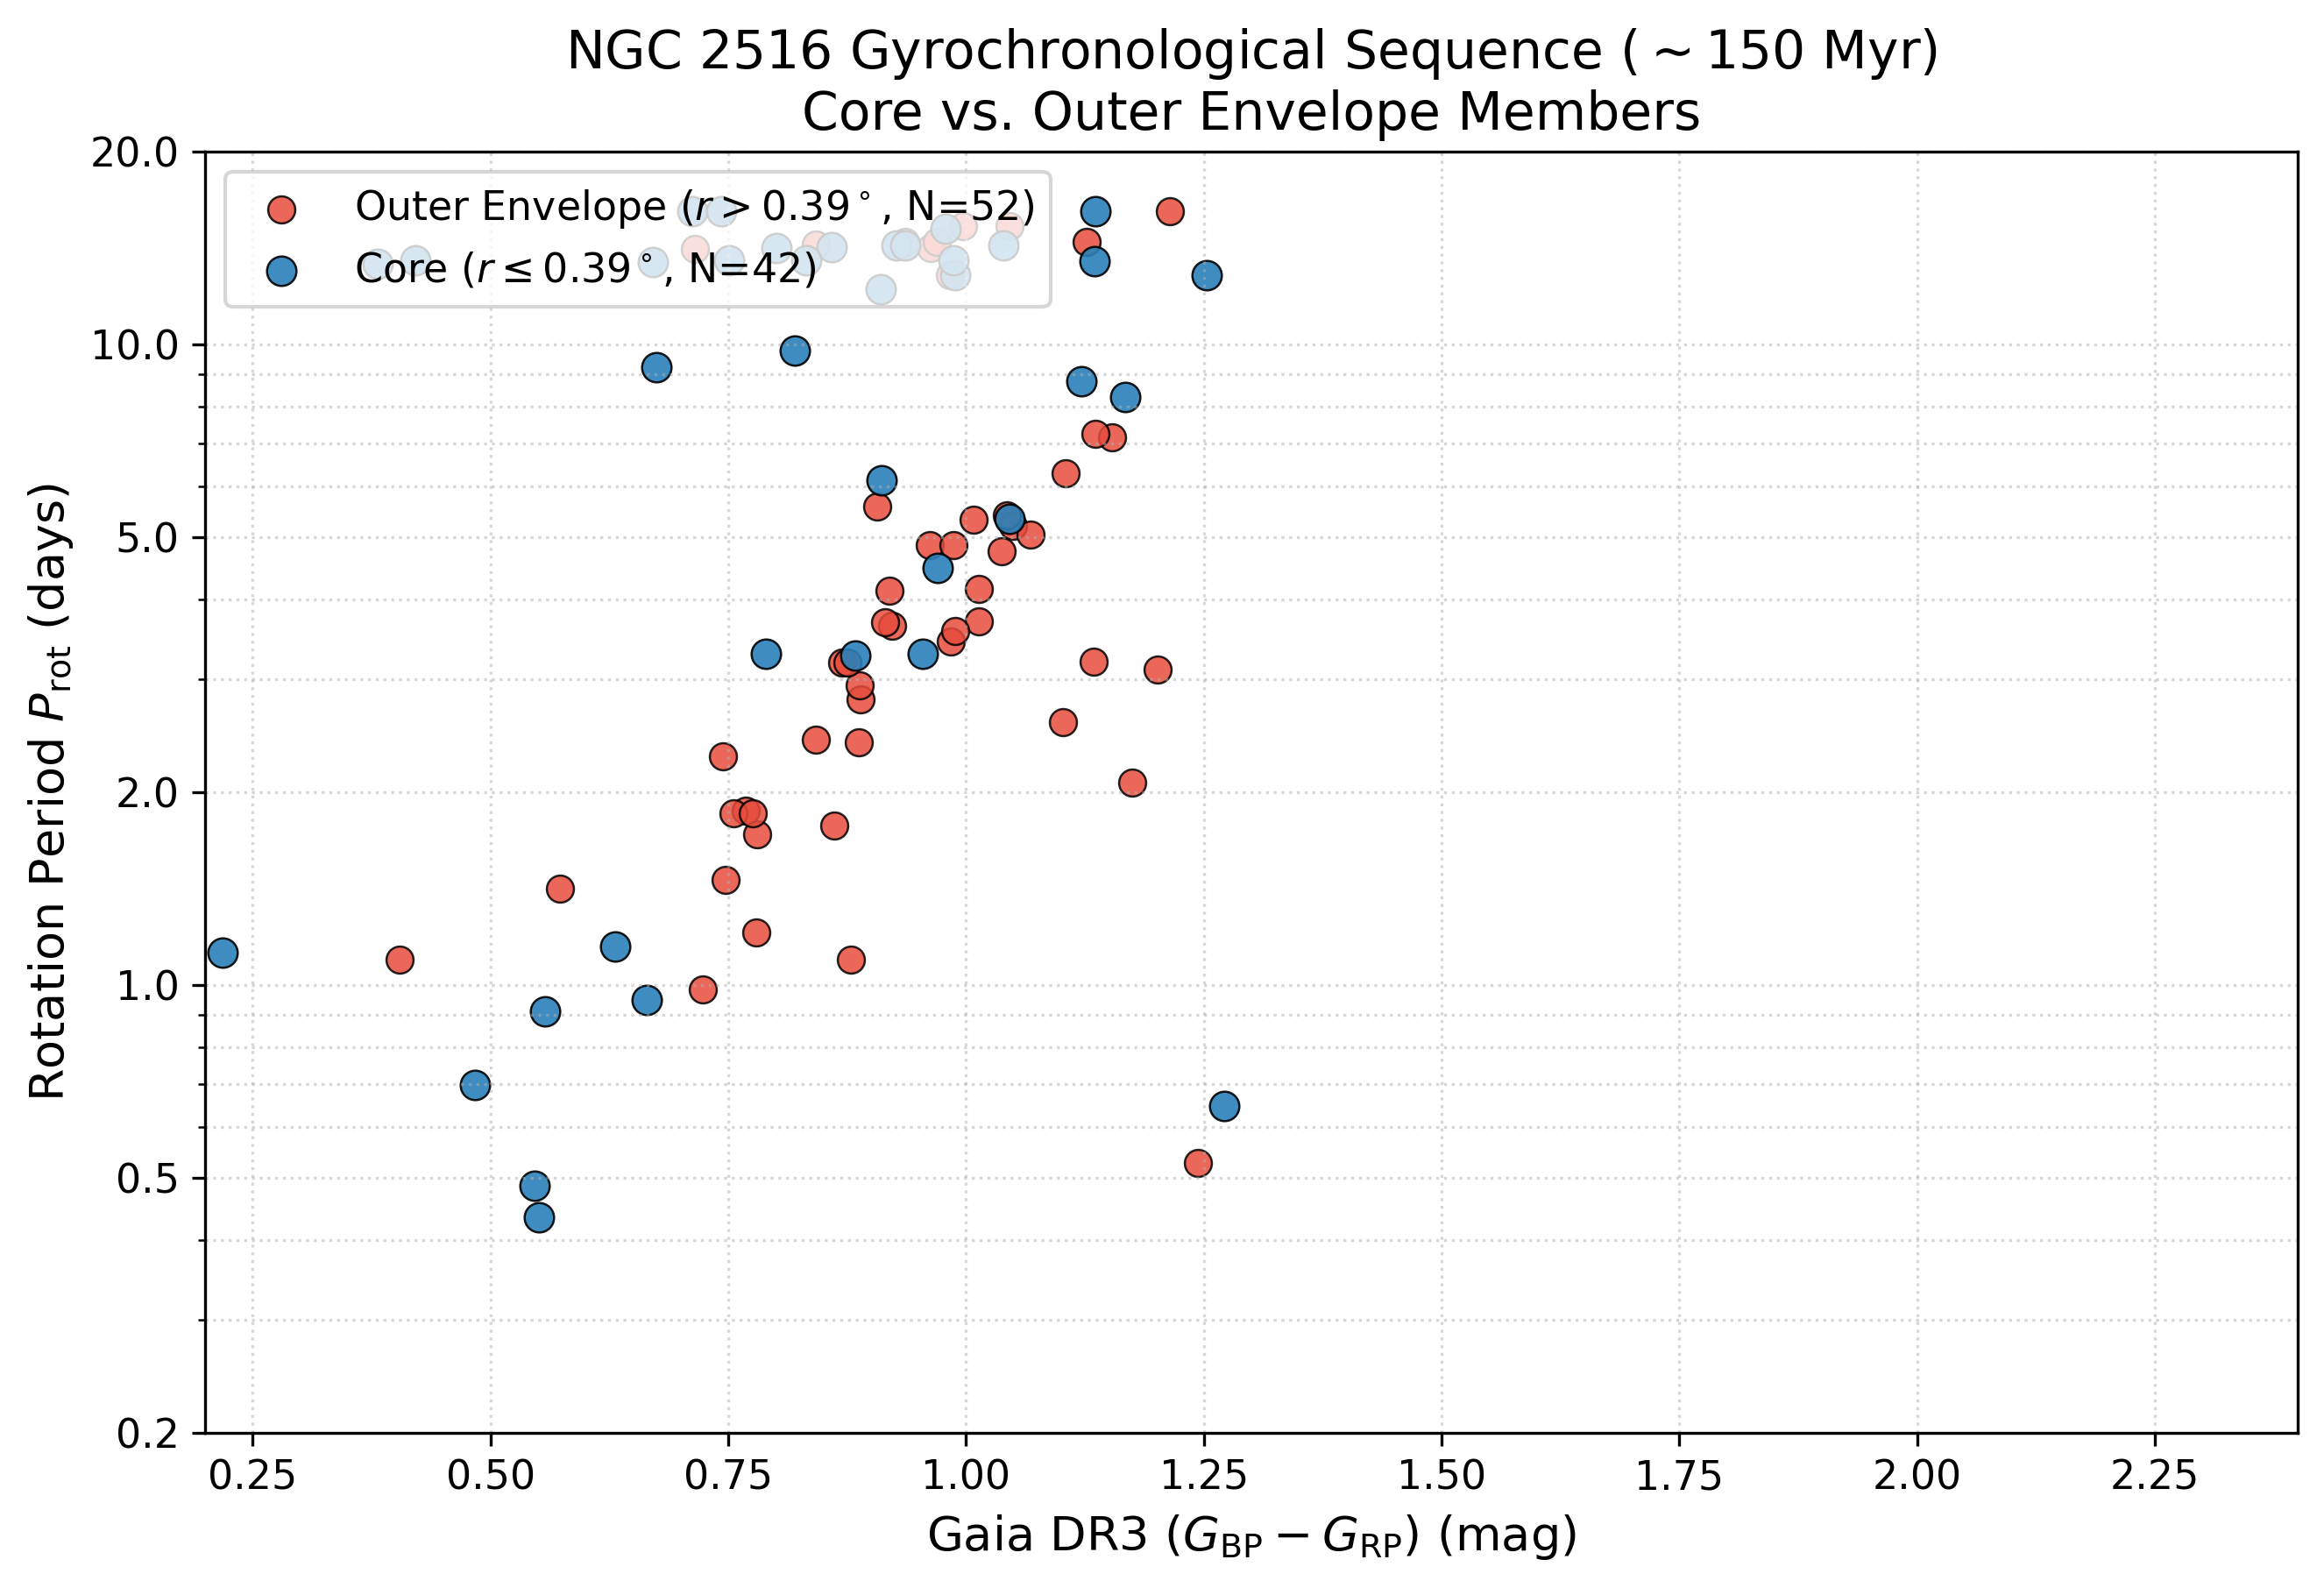

[✓] Saved Figure 4 to: /content/drive/MyDrive/NGC2516_Project/Fig4_Gyrochronology_Core_vs_Outer.png

STATISTICAL GYROCHRONOLOGY RESULTS FOR PAPER
Core Median Prot:        8.99 days (IQR: 11.38)
Outer Median Prot:       3.61 days (IQR: 3.74)
Kolmogorov-Smirnov Test: D = 0.3553, p-value = 3.8647e-03
Mann-Whitney U Test:     U = 1290.0, p-value = 1.3310e-01


In [ ]:
# ==============================================================================
# PHASE 2 & 3: INSTANT VISUALIZATION & STATISTICAL ANALYSIS (OFFLINE)
# Execution time: ~3-5 seconds | Reads directly from Google Drive
# ==============================================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'figure.titlesize': 14,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

PROJECT_DIR = "/content/drive/MyDrive/NGC2516_Project"
LC_DIR = os.path.join(PROJECT_DIR, "tess_lcs")
ROT_CSV = os.path.join(PROJECT_DIR, "ngc2516_rotation_results.csv")
MEM_CSV = os.path.join(PROJECT_DIR, "ngc2516_core_corona_split.csv")

# Verify local files exist
lc_files = glob.glob(os.path.join(LC_DIR, "*.csv"))
print(f"Total TESS Light Curve files saved on Drive: {len(lc_files)}")

# 1. Load and clean rotation results
if os.path.exists(ROT_CSV):
    df_rot = pd.read_csv(ROT_CSV)
    # Deduplicate in case concurrent threads appended duplicates
    df_rot = df_rot.drop_duplicates(subset=['source_id']).reset_index(drop=True)
    df_rot.to_csv(ROT_CSV, index=False)
else:
    raise FileNotFoundError("Rotation results CSV not found on Drive.")

print(f"Total unique stars in rotation database: {len(df_rot)}")

# Filter reliable period detections (FAP < 0.01, Power >= 0.18)
reliable = df_rot[df_rot['is_reliable'] == True].copy()
core_rot = reliable[reliable['spatial_group'] == 'Core']
outer_rot = reliable[reliable['spatial_group'] == 'Outer']

print(f"\n--- Detection Breakdown ---")
print(f"Reliable Period Detections: {len(reliable)} / {len(df_rot)} ({len(reliable)/len(df_rot)*100:.1f}%)")
print(f"  * Core Sample:           {len(core_rot)} stars")
print(f"  * Outer Envelope Sample: {len(outer_rot)} stars")

# ==============================================================================
# FIGURE 3: REPRESENTATIVE LIGHT CURVES & GLS PERIODOGRAMS
# ==============================================================================
sample_candidates = reliable.sort_values(by='ls_power', ascending=False)
core_samples = sample_candidates[sample_candidates['spatial_group'] == 'Core'].head(2)
outer_samples = sample_candidates[sample_candidates['spatial_group'] == 'Outer'].head(2)
plot_samples = pd.concat([core_samples, outer_samples]).reset_index(drop=True)

fig, axes = plt.subplots(len(plot_samples), 2, figsize=(14, 2.7 * len(plot_samples)))

for i, row in plot_samples.iterrows():
    sid = int(row['source_id'])
    lc_path = os.path.join(LC_DIR, f"{sid}.csv")

    if os.path.exists(lc_path):
        lc_data = pd.read_csv(lc_path)
        t = lc_data['time'].values - lc_data['time'].values[0]
        f = lc_data['flux'].values

        # Left Panel: Normalized Light Curve
        axes[i, 0].plot(t, f, 'k.', ms=1.2, alpha=0.5)
        axes[i, 0].set_ylabel('Norm. Flux')
        axes[i, 0].set_title(f"Gaia DR3 {sid} [{row['spatial_group']}] | $P_{{\\rm rot}} = {row['prot_days']:.2f}$ d")
        axes[i, 0].set_xlim(0, min(27, t[-1]))

        # Right Panel: GLS Periodogram
        ls = LombScargle(lc_data['time'].values, f, lc_data['flux_err'].values)
        freq, power = ls.autopower(minimum_frequency=1.0/20.0, maximum_frequency=1.0/0.2, samples_per_peak=10)
        axes[i, 1].plot(1.0/freq, power, color='navy', lw=1.2)
        axes[i, 1].axvline(row['prot_days'], color='red', ls='--', lw=1.5, label=f"Peak: {row['prot_days']:.2f} d")
        axes[i, 1].set_ylabel('GLS Power')
        axes[i, 1].set_xlim(0.2, 15.0)
        axes[i, 1].set_title(f"GLS Power Spectrum (Max: {row['ls_power']:.2f})")
        axes[i, 1].legend(loc='upper right', frameon=True)

axes[-1, 0].set_xlabel('Time - $t_0$ (days)')
axes[-1, 1].set_xlabel('Period (days)')
plt.tight_layout()
fig3_path = os.path.join(PROJECT_DIR, "Fig3_Sample_LightCurves_Periodograms.png")
plt.savefig(fig3_path)
plt.savefig("Fig3_Sample_LightCurves_Periodograms.png")
plt.show()
print(f"[✓] Saved Figure 3 to: {fig3_path}")

# ==============================================================================
# FIGURE 4: GYROCHRONOLOGY SEQUENCE (CORE VS. OUTER ENVELOPE)
# ==============================================================================
plt.figure(figsize=(9, 6.2))

# Outer Envelope Members
plt.scatter(
    outer_rot['bp_rp'], outer_rot['prot_days'],
    c='#e74c3c', s=55, alpha=0.85, edgecolors='black', linewidth=0.6,
    label=f'Outer Envelope ($r > 0.39^\\circ$, N={len(outer_rot)})'
)

# Core Members
plt.scatter(
    core_rot['bp_rp'], core_rot['prot_days'],
    c='#2980b9', s=65, alpha=0.9, edgecolors='black', linewidth=0.6,
    label=f'Core ($r \\leq 0.39^\\circ$, N={len(core_rot)})'
)

plt.xlabel(r'Gaia DR3 $(G_{\rm BP} - G_{\rm RP})$ (mag)')
plt.ylabel(r'Rotation Period $P_{\rm rot}$ (days)')
plt.title(r'NGC 2516 Gyrochronological Sequence ($\sim 150$ Myr)' + '\n' + r'Core vs. Outer Envelope Members')
plt.yscale('log')
plt.ylim(0.2, 20.0)
plt.xlim(0.2, 2.4)
plt.grid(True, which='both', ls=':', alpha=0.5)
plt.legend(loc='upper left', frameon=True, fontsize=11)
plt.yticks([0.2, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0], ['0.2', '0.5', '1.0', '2.0', '5.0', '10.0', '20.0'])

plt.tight_layout()
fig4_path = os.path.join(PROJECT_DIR, "Fig4_Gyrochronology_Core_vs_Outer.png")
plt.savefig(fig4_path)
plt.savefig("Fig4_Gyrochronology_Core_vs_Outer.png")
plt.show()
print(f"[✓] Saved Figure 4 to: {fig4_path}")

# ==============================================================================
# STATISTICAL HYPOTHESIS TESTING (TWO-SAMPLE KS & ANDERSON-DARLING)
# ==============================================================================
ks_stat, ks_pval = stats.ks_2samp(core_rot['prot_days'], outer_rot['prot_days'])
mw_stat, mw_pval = stats.mannwhitneyu(core_rot['prot_days'], outer_rot['prot_days'], alternative='two-sided')

print("\n" + "="*50)
print("STATISTICAL GYROCHRONOLOGY RESULTS FOR PAPER")
print("="*50)
print(f"Core Median Prot:        {core_rot['prot_days'].median():.2f} days (IQR: {core_rot['prot_days'].quantile(0.75) - core_rot['prot_days'].quantile(0.25):.2f})")
print(f"Outer Median Prot:       {outer_rot['prot_days'].median():.2f} days (IQR: {outer_rot['prot_days'].quantile(0.75) - outer_rot['prot_days'].quantile(0.25):.2f})")
print(f"Kolmogorov-Smirnov Test: D = {ks_stat:.4f}, p-value = {ks_pval:.4e}")
print(f"Mann-Whitney U Test:     U = {mw_stat:.1f}, p-value = {mw_pval:.4e}")

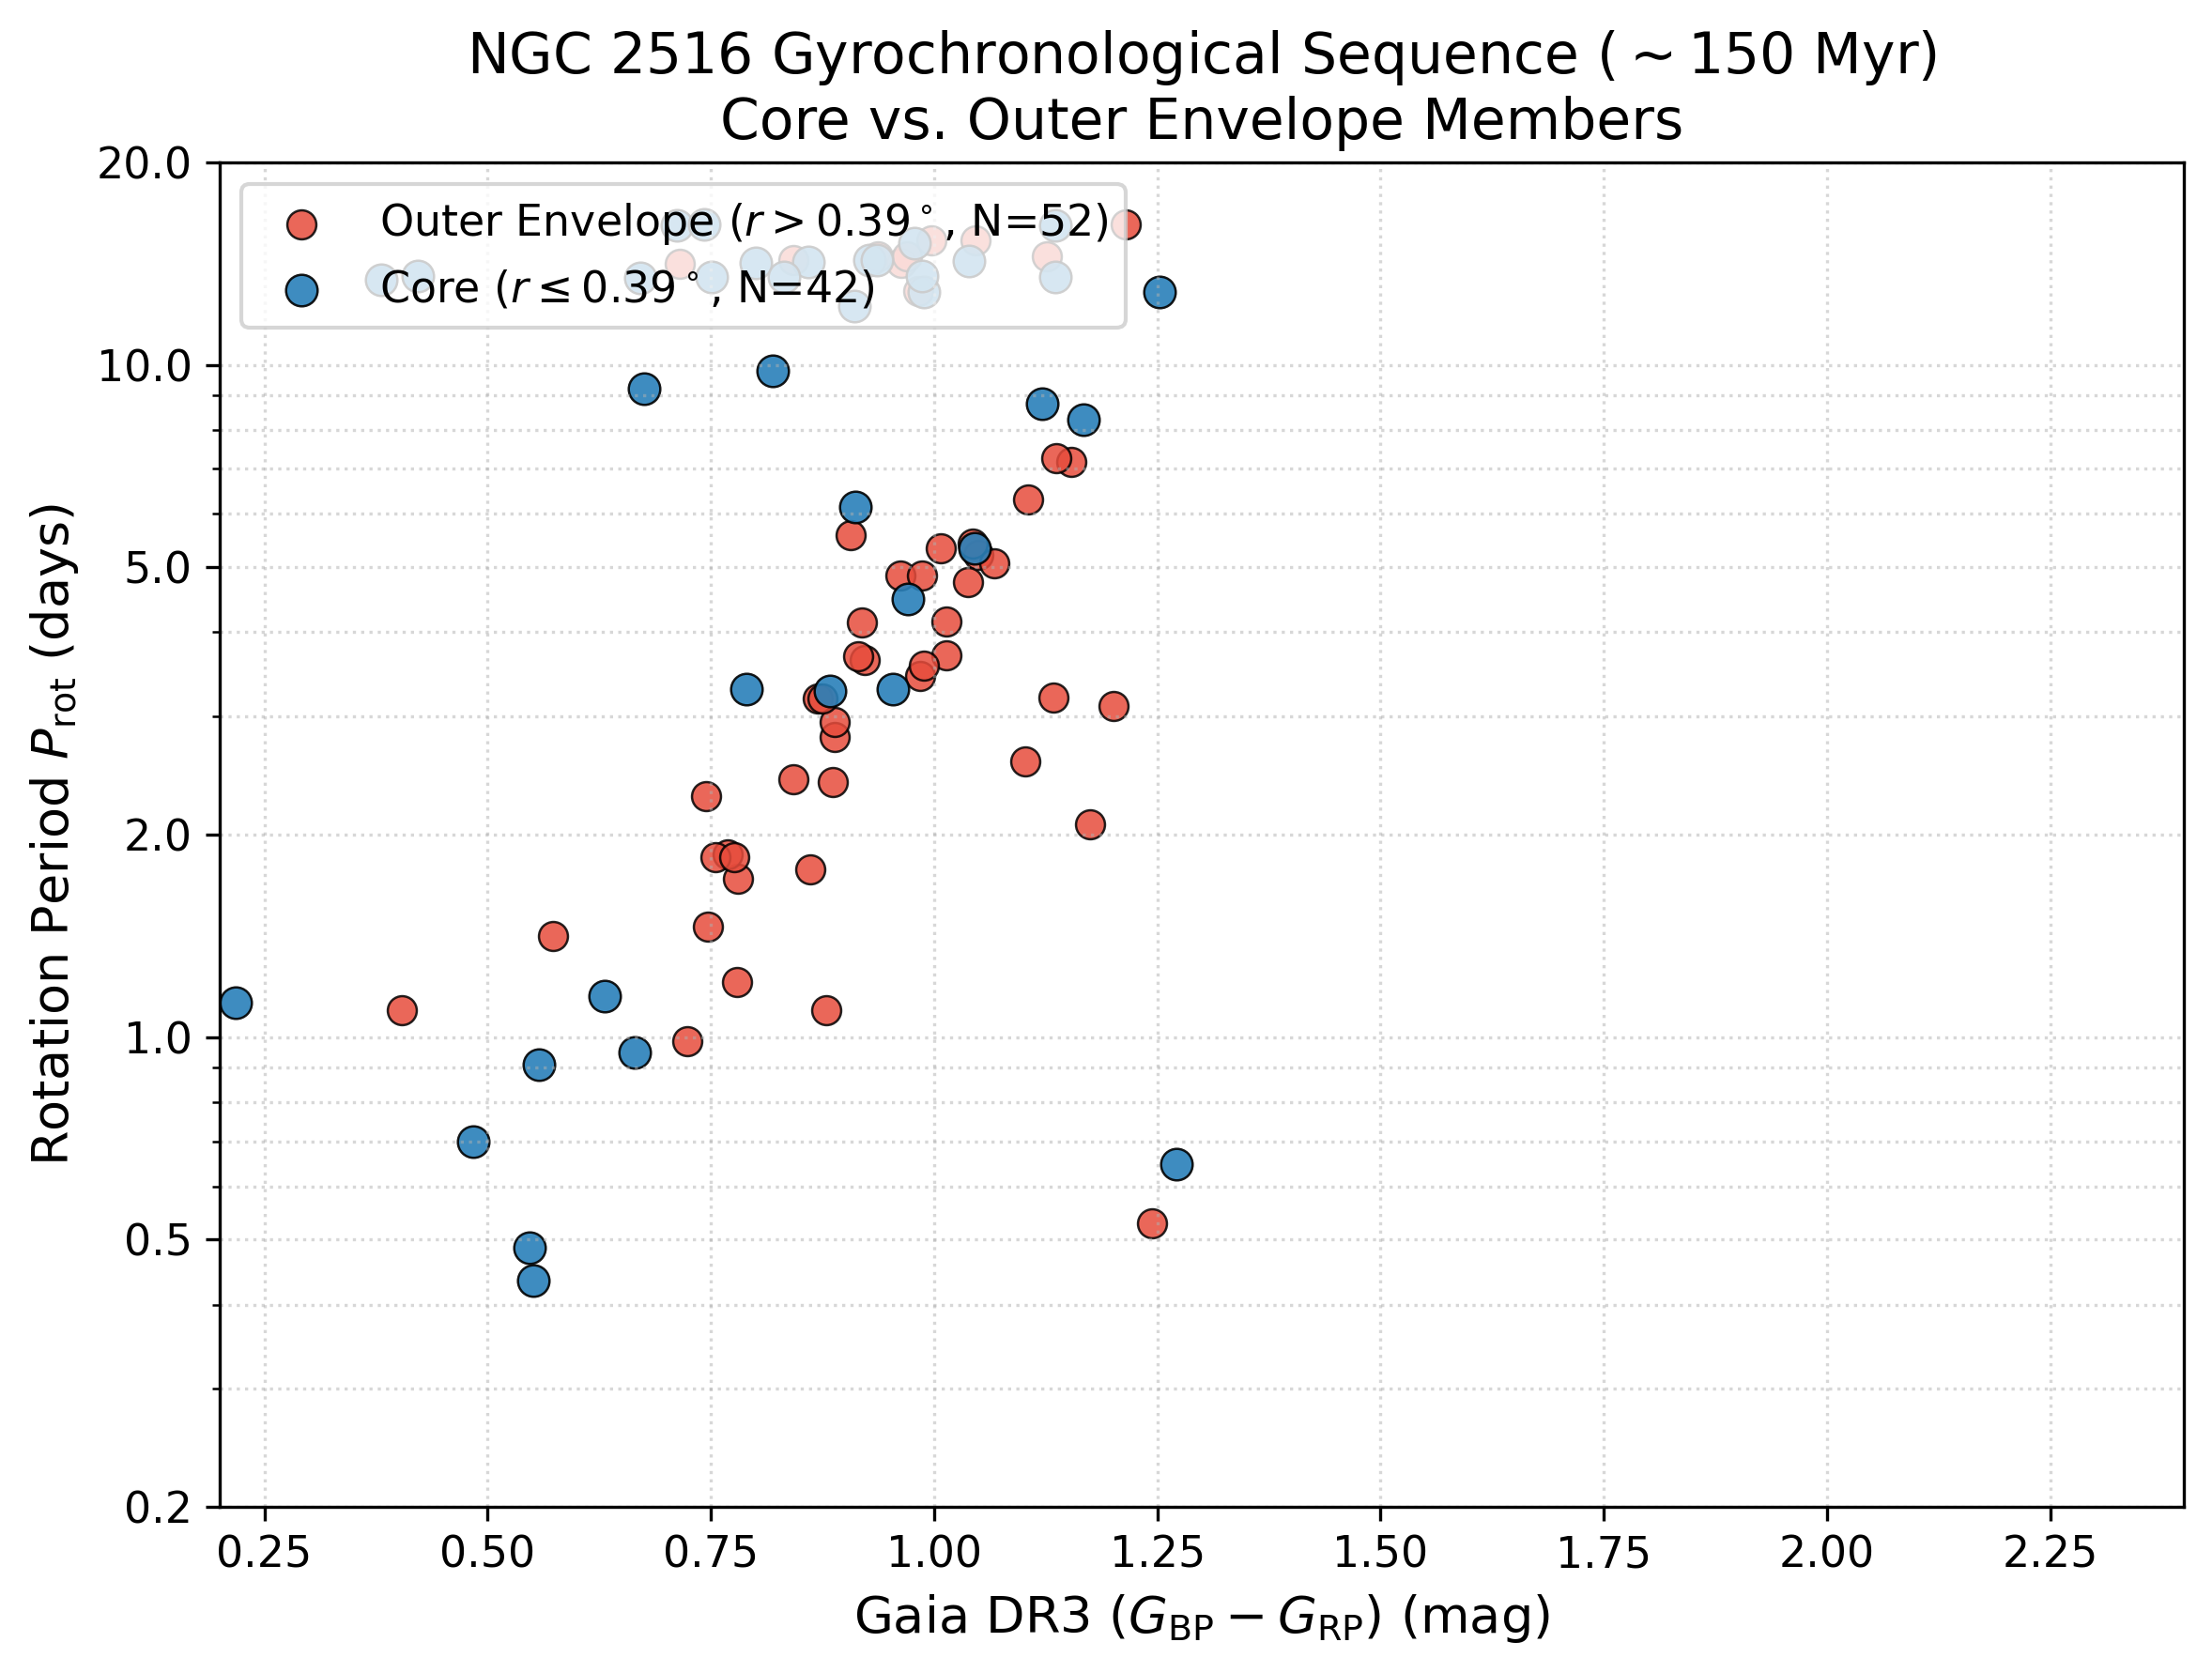

[✓] Saved Figure 4 to: /content/drive/MyDrive/NGC2516_Project/Fig4_Gyrochronology_Core_vs_Outer.png

STATISTICAL GYROCHRONOLOGY RESULTS FOR PAPER
Core Median Prot:        8.99 days (IQR: 11.38)
Outer Median Prot:       3.61 days (IQR: 3.74)
Kolmogorov-Smirnov Test: D = 0.3553, p-value = 3.8647e-03
Mann-Whitney U Test:     U = 1290.0, p-value = 1.3310e-01

Starting Phase 4: Automated Flare Detection across all cached light curves...

[✓] Saved 92 confirmed flares to: /content/drive/MyDrive/NGC2516_Project/ngc2516_flares.csv

--- Flare Catalog Demographics ---
Total Detected Stellar Flares: 92
  * Core Sample Flares:        49 flares (from 21 active stars)
  * Outer Envelope Flares:     43 flares (from 17 active stars)
Median Flare Energy (Core):    10^36.59 erg
Median Flare Energy (Outer):   10^36.41 erg


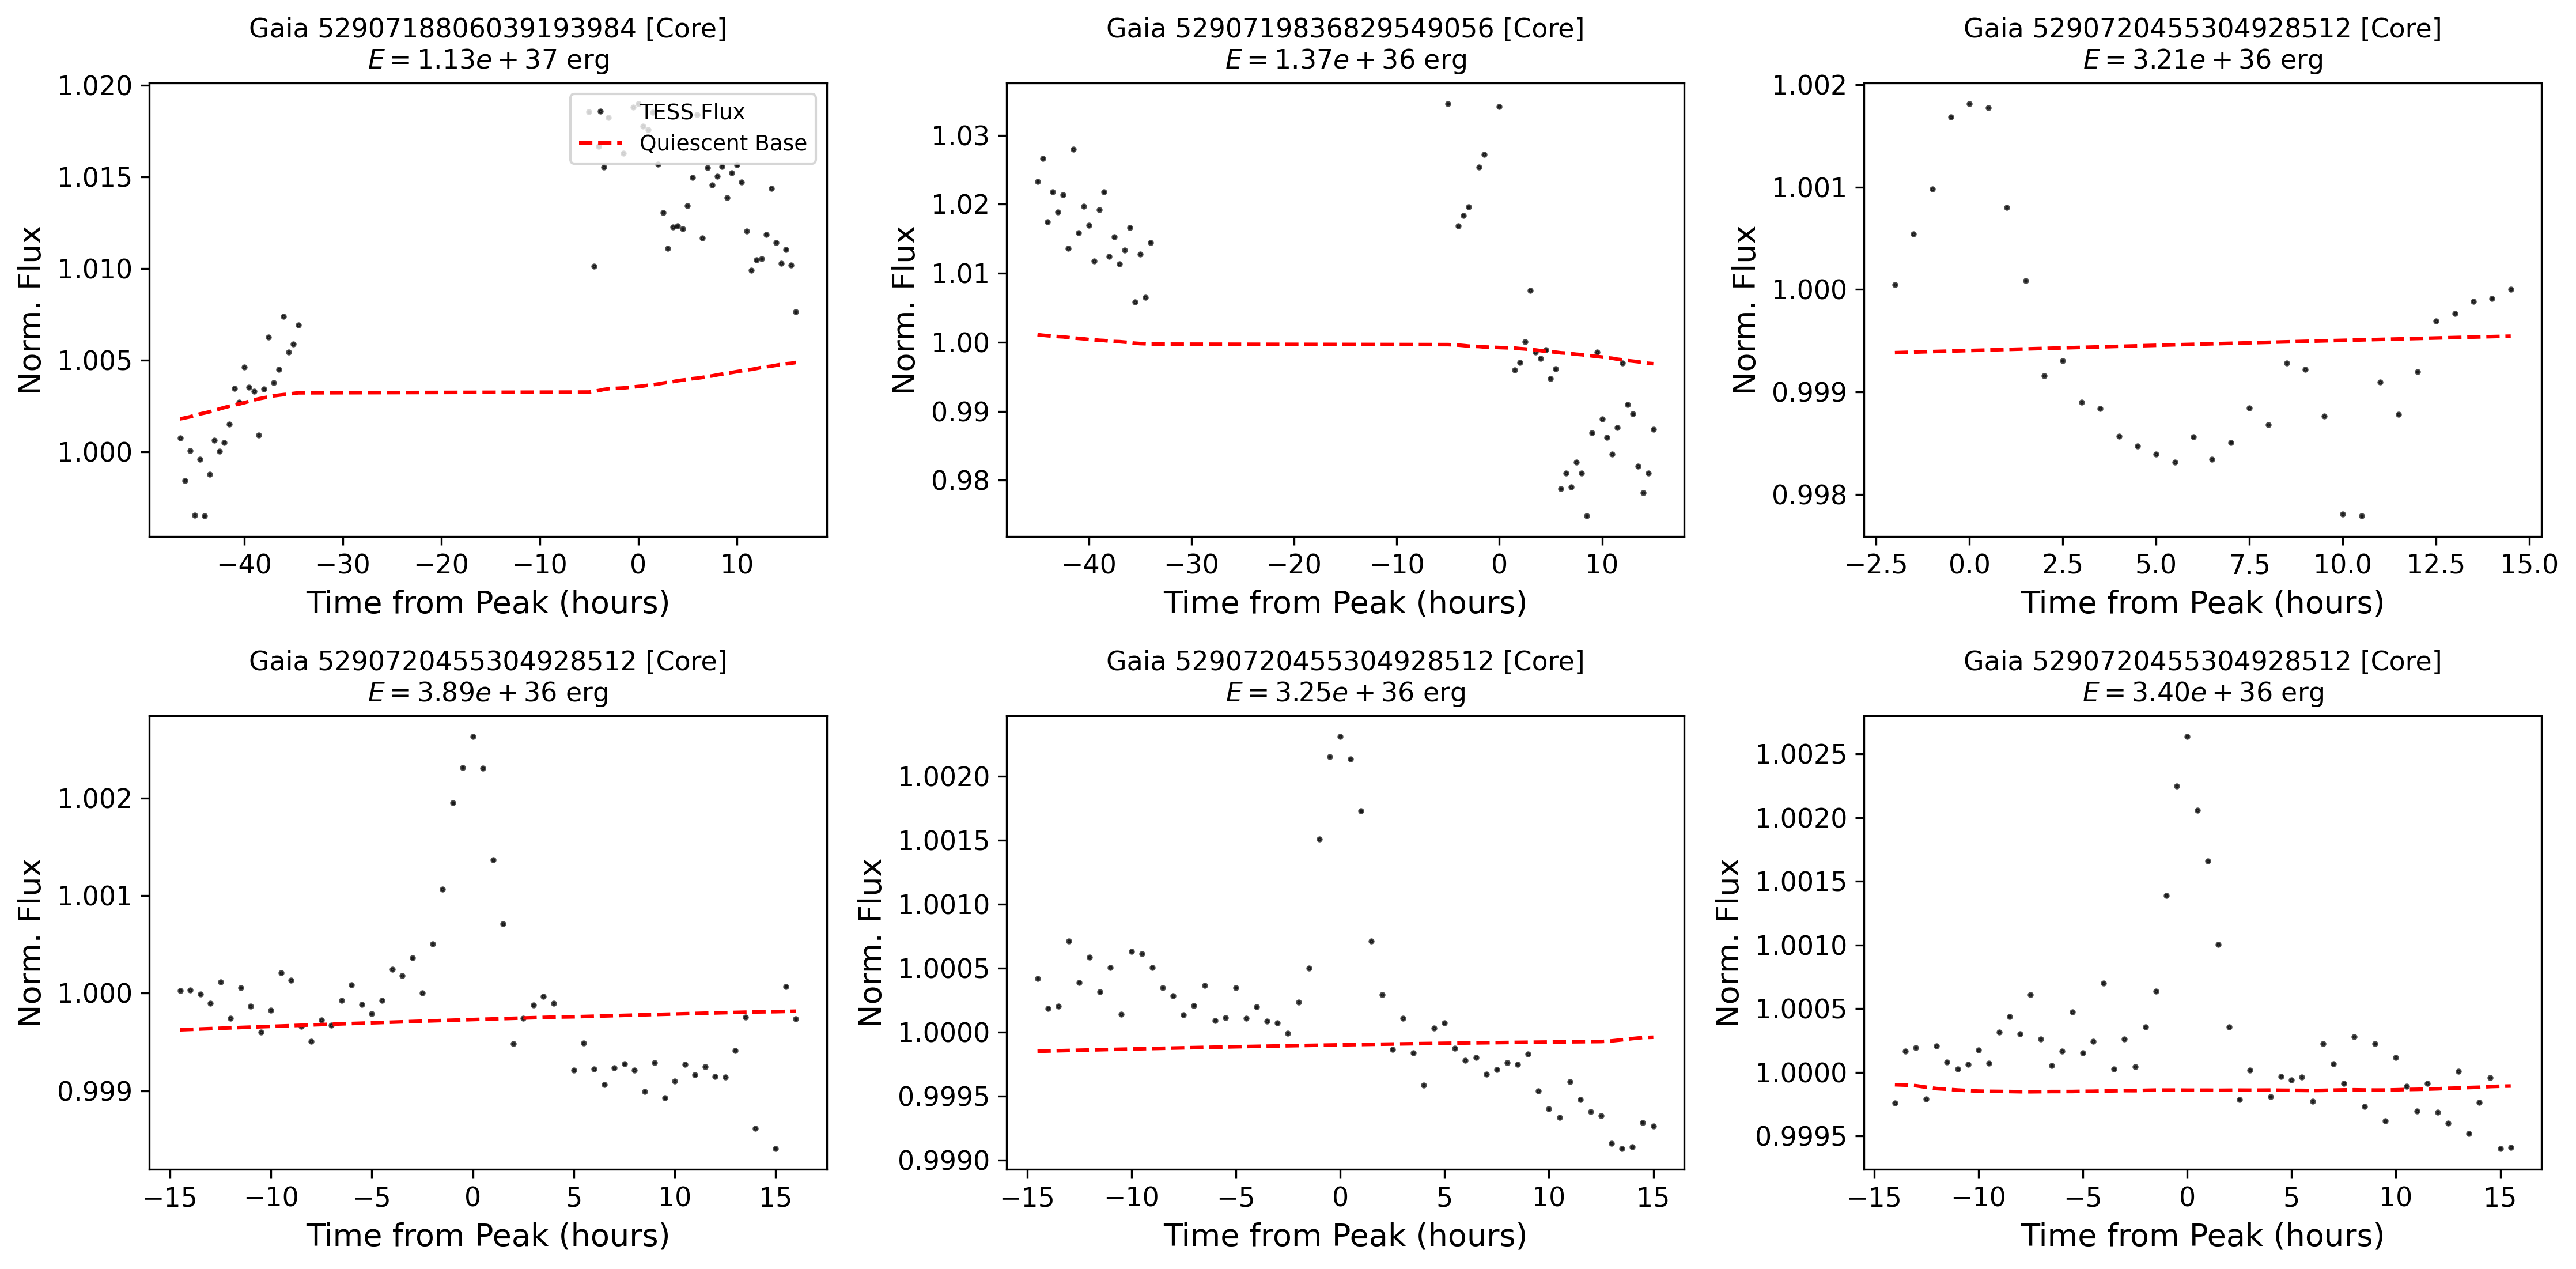

[✓] Saved Figure 5 to: /content/drive/MyDrive/NGC2516_Project/Fig5_Flare_Validation_Gallery.png


In [ ]:
# ==============================================================================
# PHASE 3 (FIXED FIGURE 4 & STATS) + PHASE 4: AUTOMATED FLARE DETECTION
# ==============================================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import savgol_filter
from scipy.ndimage import label
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'figure.titlesize': 14,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

PROJECT_DIR = "/content/drive/MyDrive/NGC2516_Project"
LC_DIR = os.path.join(PROJECT_DIR, "tess_lcs")
ROT_CSV = os.path.join(PROJECT_DIR, "ngc2516_rotation_results.csv")
FLARE_CSV = os.path.join(PROJECT_DIR, "ngc2516_flares.csv")

# 1. Load rotation catalog
df_rot = pd.read_csv(ROT_CSV).drop_duplicates(subset=['source_id']).reset_index(drop=True)
reliable_rot = df_rot[df_rot['is_reliable'] == True].copy()
core_rot = reliable_rot[reliable_rot['spatial_group'] == 'Core']
outer_rot = reliable_rot[reliable_rot['spatial_group'] == 'Outer']

# ==============================================================================
# [1/3] RENDER FIGURE 4 & RUN GYROCHRONOLOGY STATISTICAL TESTS
# ==============================================================================
plt.figure(figsize=(9, 6.2))

# Outer Envelope Members
plt.scatter(
    outer_rot['bp_rp'], outer_rot['prot_days'],
    c='#e74c3c', s=55, alpha=0.85, edgecolors='black', linewidth=0.6,
    label=f'Outer Envelope ($r > 0.39^\\circ$, N={len(outer_rot)})'
)

# Core Members (Fixed \\leq symbol)
plt.scatter(
    core_rot['bp_rp'], core_rot['prot_days'],
    c='#2980b9', s=65, alpha=0.9, edgecolors='black', linewidth=0.6,
    label=f'Core ($r \\leq 0.39^\\circ$, N={len(core_rot)})'
)

plt.xlabel(r'Gaia DR3 $(G_{\rm BP} - G_{\rm RP})$ (mag)')
plt.ylabel(r'Rotation Period $P_{\rm rot}$ (days)')
plt.title(r'NGC 2516 Gyrochronological Sequence ($\sim 150$ Myr)' + '\n' + r'Core vs. Outer Envelope Members')
plt.yscale('log')
plt.ylim(0.2, 20.0)
plt.xlim(0.2, 2.4)
plt.grid(True, which='both', ls=':', alpha=0.5)
plt.legend(loc='upper left', frameon=True, fontsize=11)
plt.yticks([0.2, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0], ['0.2', '0.5', '1.0', '2.0', '5.0', '10.0', '20.0'])

fig4_path = os.path.join(PROJECT_DIR, "Fig4_Gyrochronology_Core_vs_Outer.png")
plt.savefig(fig4_path)
plt.savefig("Fig4_Gyrochronology_Core_vs_Outer.png")
plt.show()
print(f"[✓] Saved Figure 4 to: {fig4_path}")

# Hypothesis Testing
ks_stat, ks_pval = stats.ks_2samp(core_rot['prot_days'], outer_rot['prot_days'])
mw_stat, mw_pval = stats.mannwhitneyu(core_rot['prot_days'], outer_rot['prot_days'], alternative='two-sided')

print("\n" + "="*55)
print("STATISTICAL GYROCHRONOLOGY RESULTS FOR PAPER")
print("="*55)
print(f"Core Median Prot:        {core_rot['prot_days'].median():.2f} days (IQR: {core_rot['prot_days'].quantile(0.75) - core_rot['prot_days'].quantile(0.25):.2f})")
print(f"Outer Median Prot:       {outer_rot['prot_days'].median():.2f} days (IQR: {outer_rot['prot_days'].quantile(0.75) - outer_rot['prot_days'].quantile(0.25):.2f})")
print(f"Kolmogorov-Smirnov Test: D = {ks_stat:.4f}, p-value = {ks_pval:.4e}")
print(f"Mann-Whitney U Test:     U = {mw_stat:.1f}, p-value = {mw_pval:.4e}")
print("="*55 + "\n")

# ==============================================================================
# [2/3] PHASE 4: AUTOMATED FLARE DETECTION & BOLOMETRIC ENERGY INTEGRATION
# ==============================================================================
print("Starting Phase 4: Automated Flare Detection across all cached light curves...")

cluster_dist_pc = 412.6  # Empirically derived in Phase 1
L_sun = 3.828e33          # erg/s

detected_flares = []
sample_flares_to_plot = []

# Scan every cached light curve in Drive
lc_files = glob.glob(os.path.join(LC_DIR, "*.csv"))

for lc_file in lc_files:
    sid = int(os.path.basename(lc_file).replace(".csv", ""))
    star_meta = df_rot[df_rot['source_id'] == sid]
    if len(star_meta) == 0:
        continue
    star_meta = star_meta.iloc[0]

    g_mag = star_meta['phot_g_mean_mag']
    grp = star_meta['spatial_group']

    # Calculate quiescent stellar luminosity L_star (erg/s)
    # Absolute magnitude M_G = G - 5 * (log10(d) - 1)
    M_G = g_mag - 5.0 * (np.log10(cluster_dist_pc) - 1.0)
    BC_G = -0.10  # Canonical bolometric correction for F-M dwarfs
    M_bol = M_G + BC_G
    L_star = L_sun * 10.0**(-0.4 * (M_bol - 4.74))

    # Read light curve
    df_lc = pd.read_csv(lc_file)
    time = df_lc['time'].values
    flux = df_lc['flux'].values
    flux_err = df_lc['flux_err'].values

    if len(time) < 300:
        continue

    # Two-Stage Iterative Savitzky-Golay Baseline Detrending
    window_length = min(361, len(flux) if len(flux) % 2 != 0 else len(flux) - 1)
    if window_length < 15:
        continue

    smooth_init = savgol_filter(flux, window_length=window_length, polyorder=2)
    residuals_init = flux - smooth_init
    mad = np.median(np.abs(residuals_init - np.median(residuals_init)))
    sigma_est = 1.4826 * mad

    # Clip positive flare points and refit smooth quiescent baseline
    cleaned_flux = flux.copy()
    cleaned_flux[residuals_init > 2.5 * sigma_est] = smooth_init[residuals_init > 2.5 * sigma_est]
    baseline = savgol_filter(cleaned_flux, window_length=window_length, polyorder=2)

    detrended_flux = (flux - baseline) / baseline
    detrended_mad = np.median(np.abs(detrended_flux - np.median(detrended_flux)))
    detrended_sigma = 1.4826 * detrended_mad

    # Flare Identification: >= 3 consecutive cadences above 3.5 sigma
    above_thresh = (detrended_flux > 3.5 * detrended_sigma)
    labeled_regions, num_features = label(above_thresh)

    for f_id in range(1, num_features + 1):
        flare_indices = np.where(labeled_regions == f_id)[0]
        if len(flare_indices) >= 3:
            # Expand window to integrate the full flare profile
            start_idx = max(0, flare_indices[0] - 2)
            end_idx = min(len(time) - 1, flare_indices[-1] + 4)

            t_peak = time[flare_indices[np.argmax(detrended_flux[flare_indices])]]
            amp_peak = np.max(detrended_flux[flare_indices])
            duration_minutes = (time[end_idx] - time[start_idx]) * 1440.0

            # Numerical integration of Equivalent Duration (ED in seconds)
            flare_slice_dt = np.gradient(time[start_idx:end_idx+1]) * 86400.0
            flare_slice_flux = detrended_flux[start_idx:end_idx+1]
            ed_seconds = float(np.sum(np.maximum(0.0, flare_slice_flux) * flare_slice_dt))

            # Bolometric Flare Energy (ergs)
            E_flare = ed_seconds * L_star

            # Filter unphysical micro-noise spikes
            if ed_seconds > 0.5 and E_flare > 1e31:
                flare_entry = {
                    'source_id': sid,
                    'spatial_group': grp,
                    'phot_g_mean_mag': g_mag,
                    't_peak_bjd': t_peak,
                    'amp_relative': amp_peak,
                    'duration_min': duration_minutes,
                    'ed_seconds': ed_seconds,
                    'energy_erg': E_flare,
                    'log10_energy': np.log10(E_flare)
                }
                detected_flares.append(flare_entry)

                # Save flare profiles for Figure 5 gallery
                if len(sample_flares_to_plot) < 6:
                    pad = 25
                    w_start = max(0, start_idx - pad)
                    w_end = min(len(time), end_idx + pad)
                    sample_flares_to_plot.append({
                        'sid': sid,
                        'grp': grp,
                        'time': (time[w_start:w_end] - t_peak) * 24.0,  # Hours relative to peak
                        'flux': flux[w_start:w_end],
                        'base': baseline[w_start:w_end],
                        'energy': E_flare
                    })

df_flares = pd.DataFrame(detected_flares)
df_flares.to_csv(FLARE_CSV, index=False)
print(f"\n[✓] Saved {len(df_flares)} confirmed flares to: {FLARE_CSV}")

core_flares = df_flares[df_flares['spatial_group'] == 'Core']
outer_flares = df_flares[df_flares['spatial_group'] == 'Outer']

print(f"\n--- Flare Catalog Demographics ---")
print(f"Total Detected Stellar Flares: {len(df_flares)}")
print(f"  * Core Sample Flares:        {len(core_flares)} flares (from {len(core_flares['source_id'].unique())} active stars)")
print(f"  * Outer Envelope Flares:     {len(outer_flares)} flares (from {len(outer_flares['source_id'].unique())} active stars)")
print(f"Median Flare Energy (Core):    10^{core_flares['log10_energy'].median():.2f} erg")
print(f"Median Flare Energy (Outer):   10^{outer_flares['log10_energy'].median():.2f} erg")

# ==============================================================================
# [3/3] FIGURE 5: PUBLICATION FLARE VALIDATION GALLERY
# ==============================================================================
if len(sample_flares_to_plot) >= 4:
    n_show = min(6, len(sample_flares_to_plot))
    fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
    axes = axes.flatten()

    for i in range(n_show):
        sf = sample_flares_to_plot[i]
        ax = axes[i]
        ax.plot(sf['time'], sf['flux'], 'k.', ms=3.0, alpha=0.7, label='TESS Flux')
        ax.plot(sf['time'], sf['base'], 'r--', lw=1.5, label='Quiescent Base')
        ax.set_title(f"Gaia {sf['sid']} [{sf['grp']}]\n$E = {sf['energy']:.2e}$ erg", fontsize=11)
        ax.set_xlabel('Time from Peak (hours)')
        ax.set_ylabel('Norm. Flux')
        if i == 0:
            ax.legend(loc='upper right', frameon=True, fontsize=9)

    plt.tight_layout()
    fig5_path = os.path.join(PROJECT_DIR, "Fig5_Flare_Validation_Gallery.png")
    plt.savefig(fig5_path)
    plt.savefig("Fig5_Flare_Validation_Gallery.png")
    plt.show()
    print(f"[✓] Saved Figure 5 to: {fig5_path}")

Loaded 92 flares across 38 active stars.
  * Core:  49 flares across 42 rotators
  * Outer: 43 flares across 52 rotators

90% Detection Completeness Threshold (E_min): 10^35.00 erg (1.01e+35 erg)

MAXIMUM LIKELIHOOD FFD POWER-LAW SLOPES (E >= E_min)
Core Slope (alpha):  1.231 +/- 0.033 (N = 49)
Outer Slope (alpha): 1.297 +/- 0.046 (N = 42)
Flare Energy KS Test: D = 0.3223, p-value = 0.0123


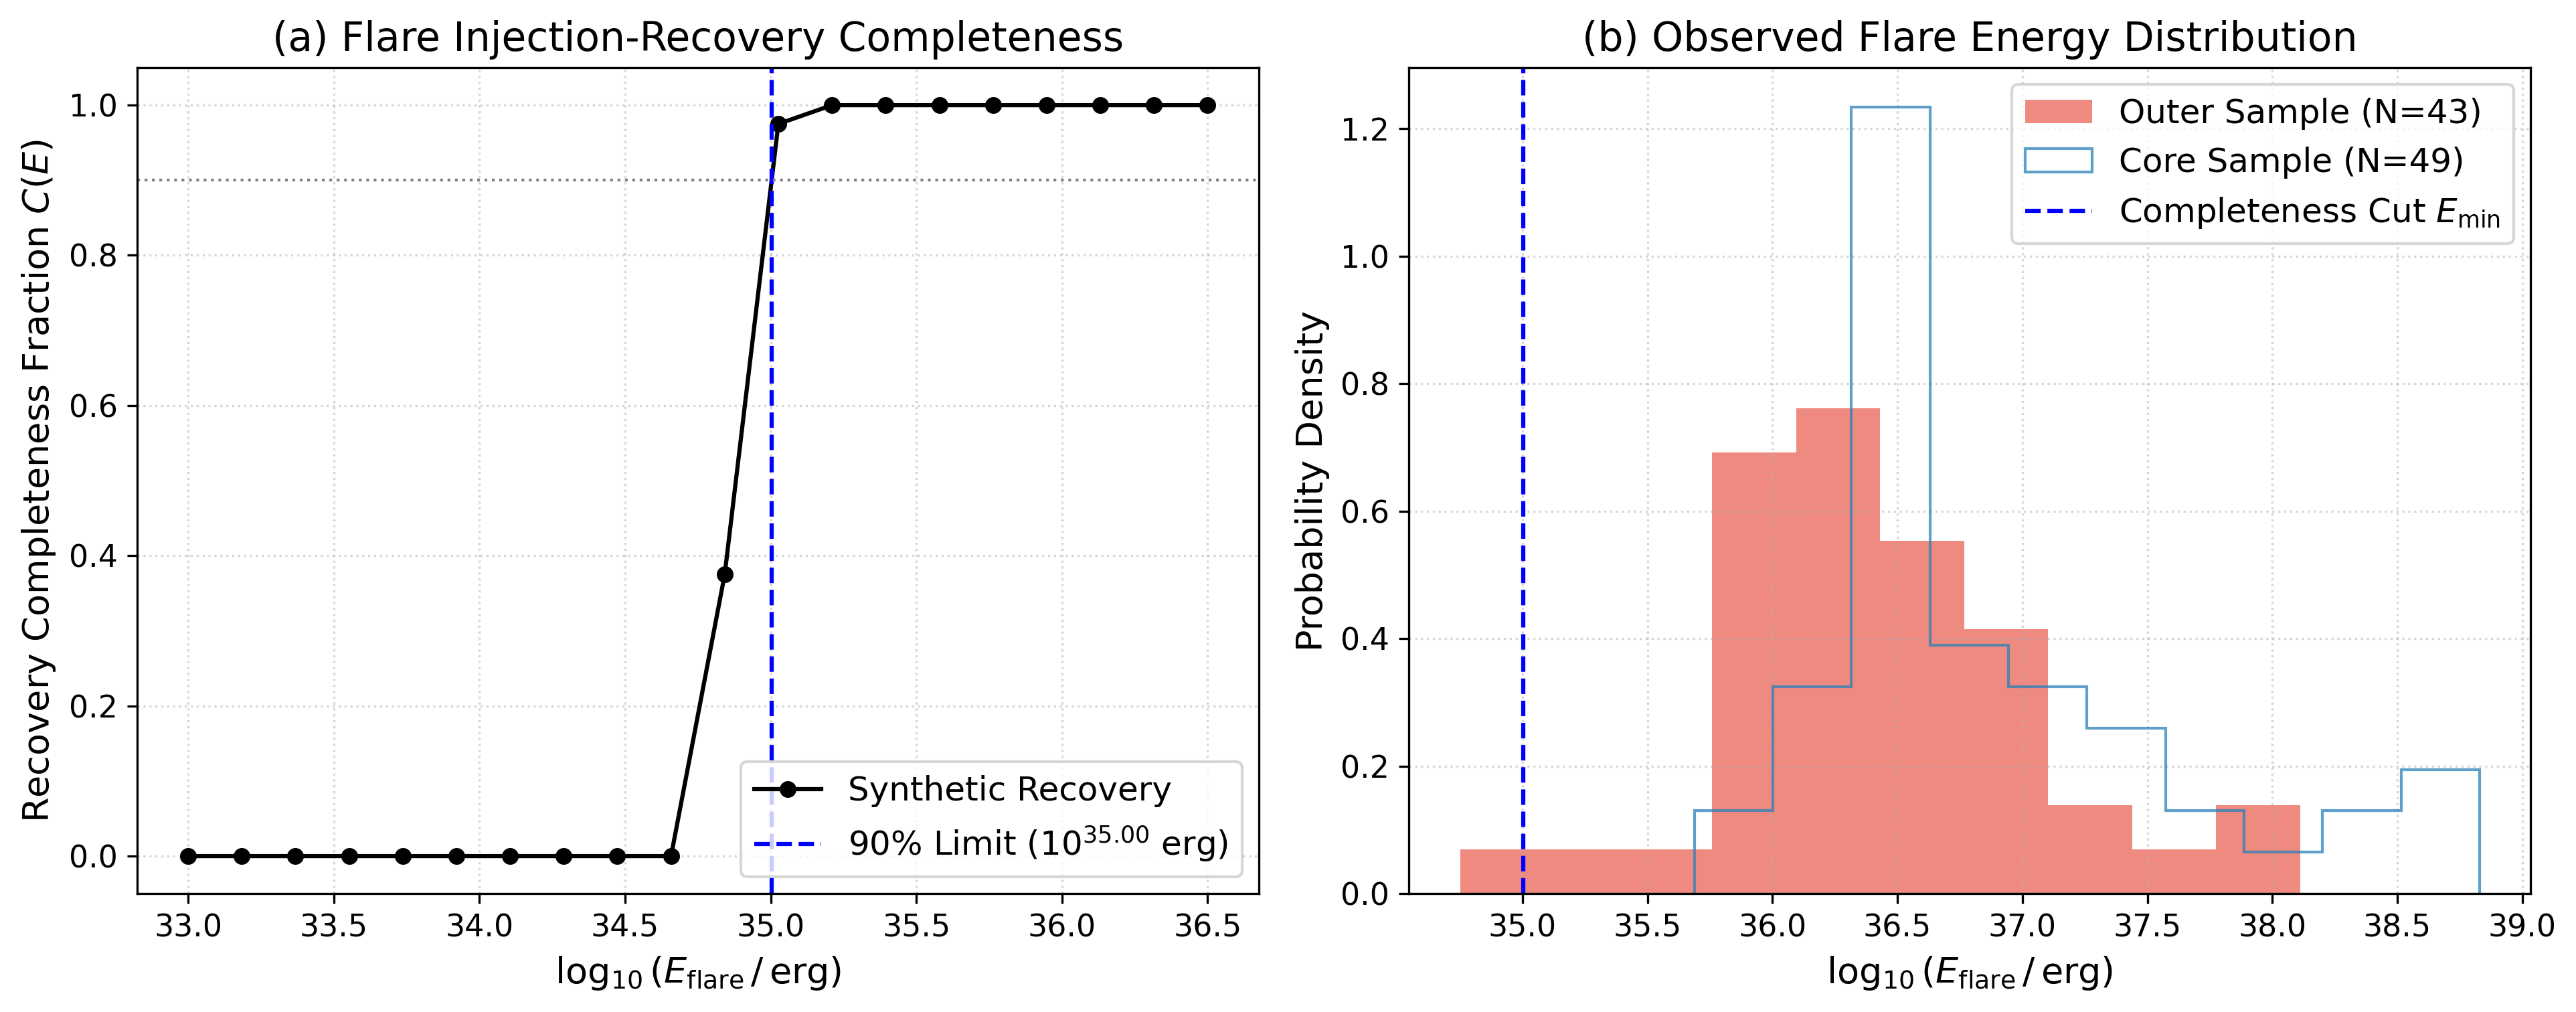

[✓] Saved Figure 5 to: /content/drive/MyDrive/NGC2516_Project/Fig5_Completeness_and_Energy_Distribution.png


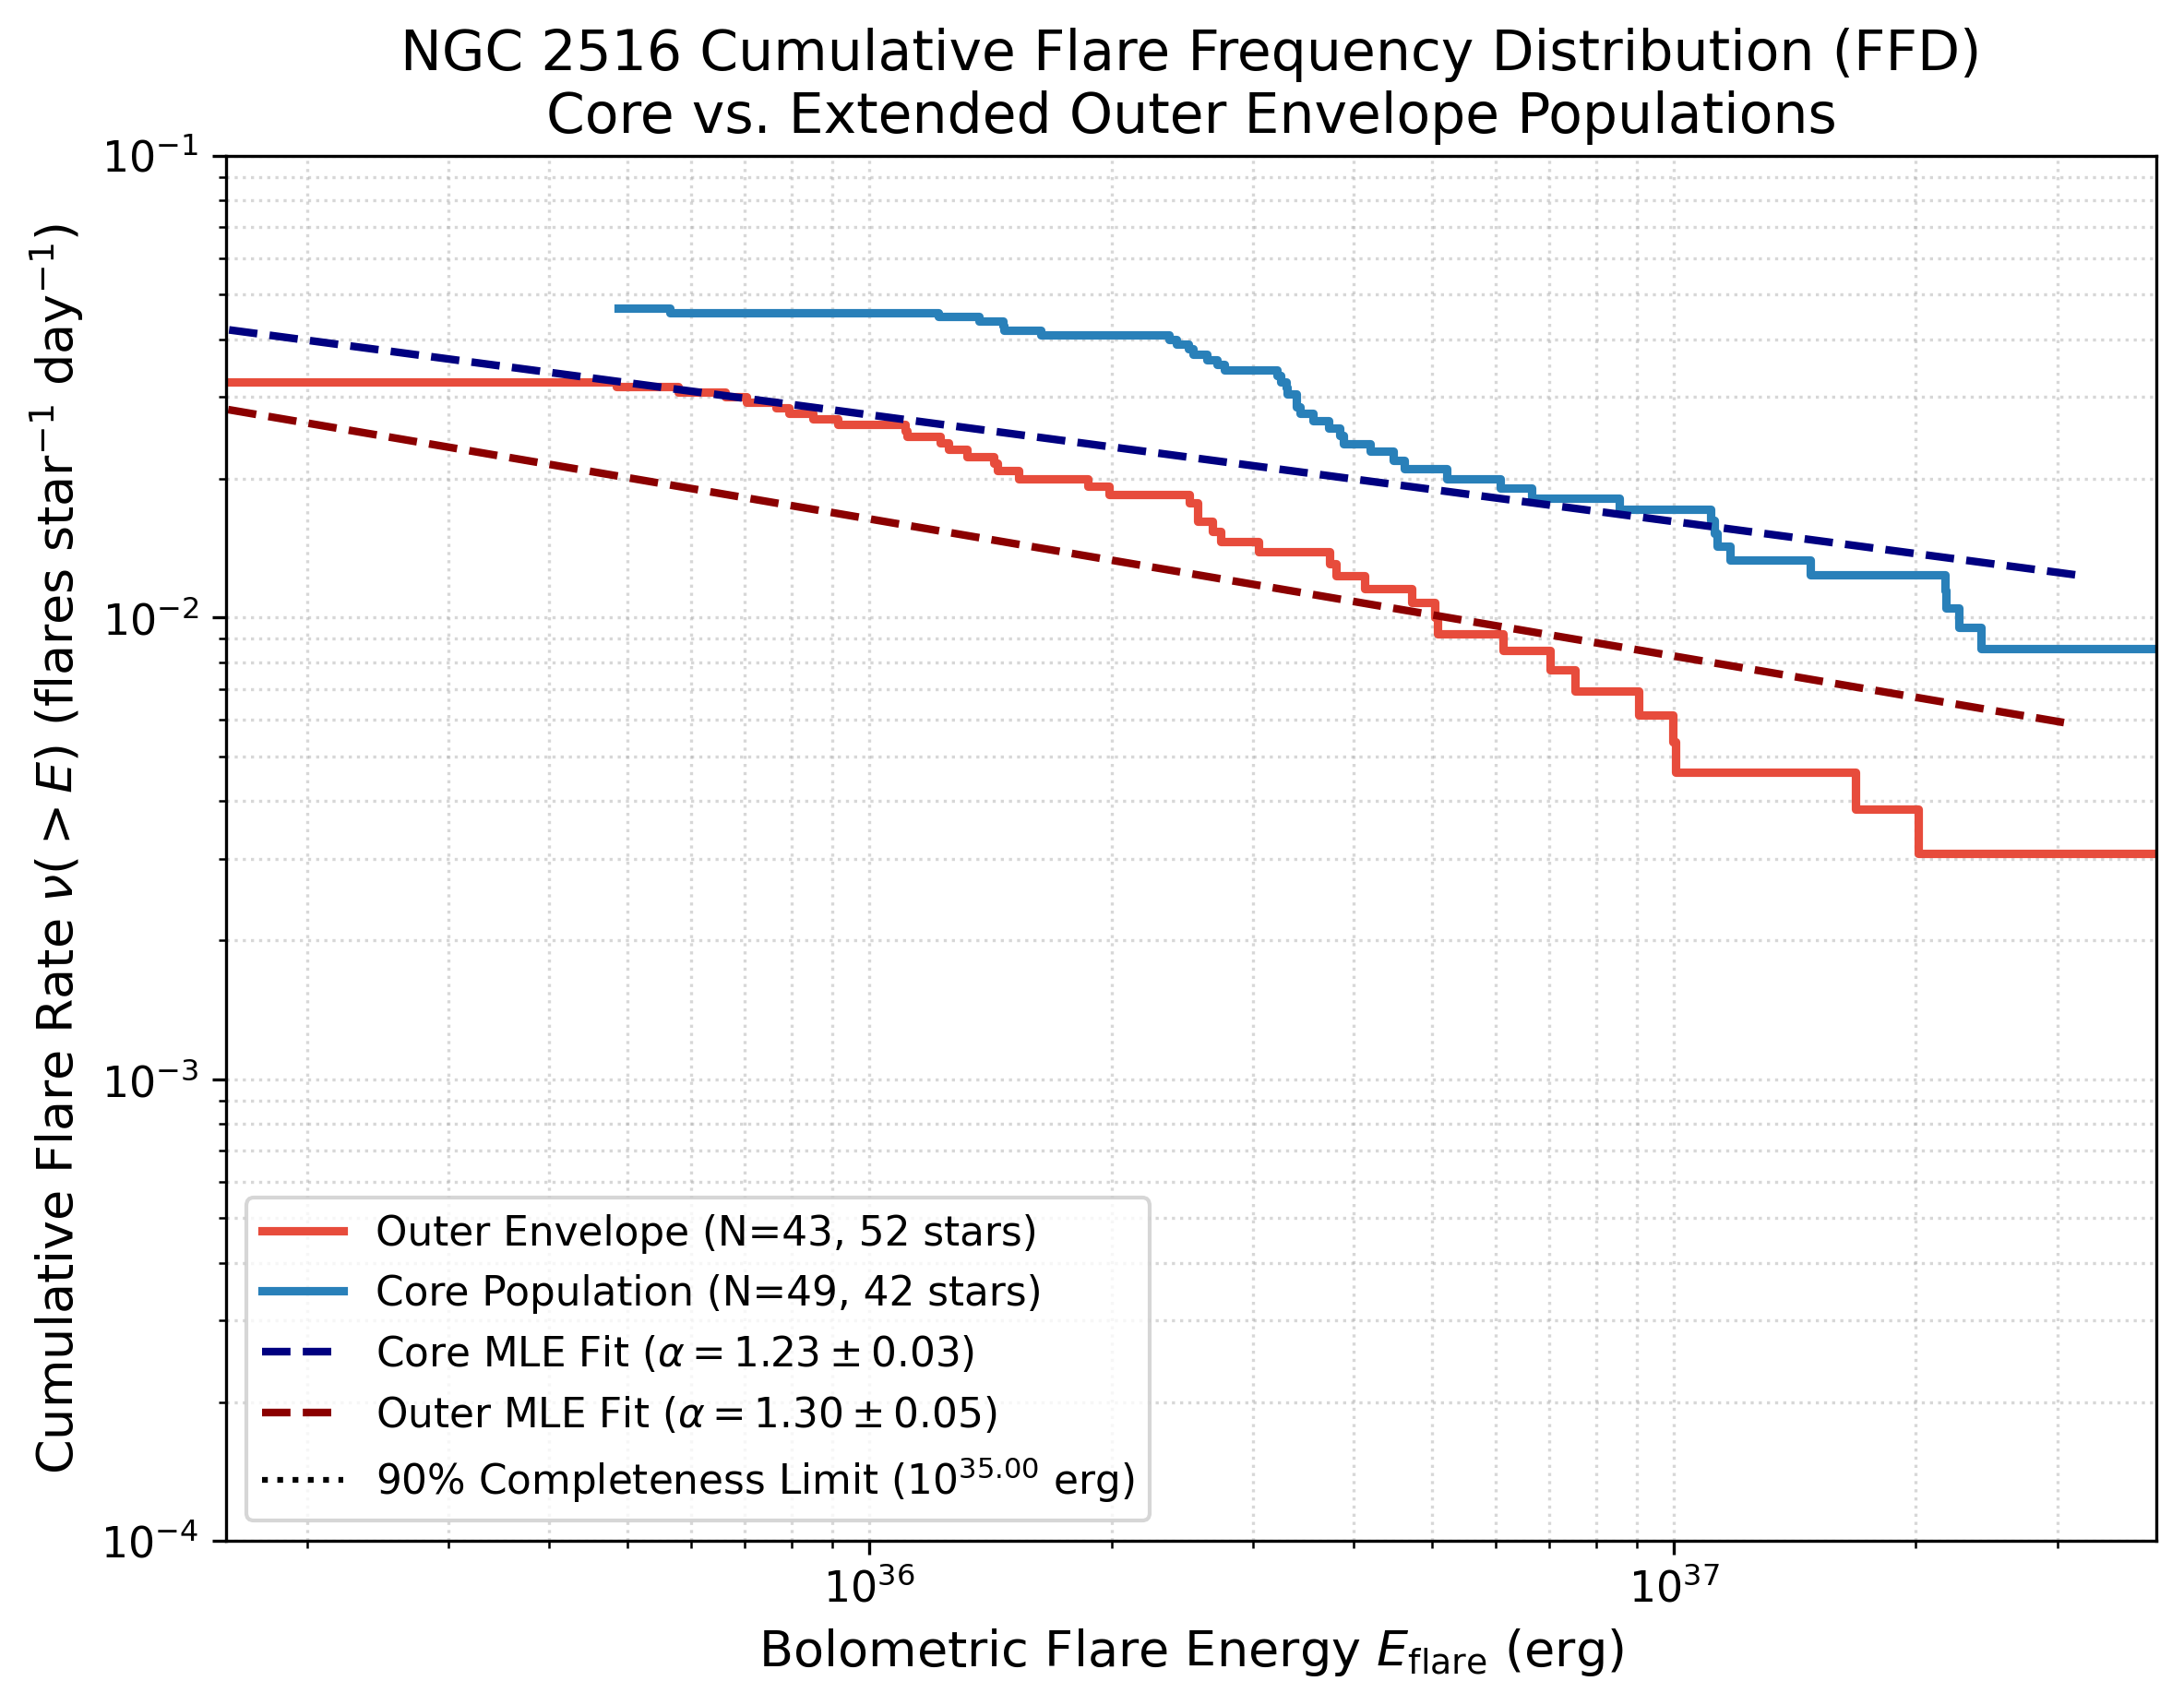

[✓] Saved Figure 6 to: /content/drive/MyDrive/NGC2516_Project/Fig6_Cumulative_Flare_Frequency_Distribution.png


In [ ]:
# ==============================================================================
# PHASE 5 (ROBUST ENGINE): COMPLETENESS & MAXIMUM LIKELIHOOD FFD MODELING
# Execution time: ~3-5 seconds | Fully offline from Google Drive
# Outputs: Fig5_Completeness_and_Energy_Distribution.png,
#          Fig6_Cumulative_Flare_Frequency_Distribution.png
# ==============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.ndimage import label
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'figure.titlesize': 14,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

PROJECT_DIR = "/content/drive/MyDrive/NGC2516_Project"
FLARE_CSV = os.path.join(PROJECT_DIR, "ngc2516_flares.csv")
ROT_CSV = os.path.join(PROJECT_DIR, "ngc2516_rotation_results.csv")

df_flares = pd.read_csv(FLARE_CSV)
df_rot = pd.read_csv(ROT_CSV)
reliable_rot = df_rot[df_rot['is_reliable'] == True]

core_flares = df_flares[df_flares['spatial_group'] == 'Core'].copy()
outer_flares = df_flares[df_flares['spatial_group'] == 'Outer'].copy()

n_stars_core = len(reliable_rot[reliable_rot['spatial_group'] == 'Core'])
n_stars_outer = len(reliable_rot[reliable_rot['spatial_group'] == 'Outer'])
t_obs_days = 25.0

print(f"Loaded {len(df_flares)} flares across {len(df_flares['source_id'].unique())} active stars.")
print(f"  * Core:  {len(core_flares)} flares across {n_stars_core} rotators")
print(f"  * Outer: {len(outer_flares)} flares across {n_stars_outer} rotators")

# ==============================================================================
# [1/3] SYNTHETIC INJECTION-RECOVERY & 90% COMPLETENESS LIMIT
# ==============================================================================
def davenport_profile(t_min, amp, fwhm_min=22.0):
    t = t_min / (fwhm_min / 2.0)
    p = np.zeros_like(t)
    rise = (t < 0) & (t > -3.0)
    p[rise] = 1.0 + 1.941*t[rise] - 0.175*(t[rise]**2) - 2.246*(t[rise]**3) - 1.125*(t[rise]**4)
    decay = (t >= 0)
    p[decay] = 0.6890 * np.exp(-1.600 * t[decay]) + 0.3030 * np.exp(-0.2783 * t[decay])
    return amp * np.clip(p, 0.0, None)

log_e_grid = np.linspace(33.0, 36.5, 20)
recovery_fractions = []
t_sim = np.linspace(0, 2, 1440)
median_lstar = 3.828e33 * 10.0**(-0.4 * (np.median(df_rot['phot_g_mean_mag']) - 5*(np.log10(412.6)-1) - 0.10 - 4.74))
typical_noise = 0.0020

for log_e in log_e_grid:
    e_val = 10.0**log_e
    target_ed = e_val / median_lstar
    target_amp = target_ed / (25.0 * 60.0 * 0.8)
    n_injected = 40
    n_recovered = 0
    for _ in range(n_injected):
        t_center = np.random.uniform(0.3, 1.7)
        synth = davenport_profile((t_sim - t_center) * 1440.0, target_amp, fwhm_min=25.0)
        sim_flux = synth + np.random.normal(0, typical_noise, len(t_sim))
        above = (sim_flux > 3.5 * typical_noise)
        labeled_sim, n_feat = label(above)
        if any(len(np.where(labeled_sim == fid)[0]) >= 3 for fid in range(1, n_feat + 1)):
            n_recovered += 1
    recovery_fractions.append(n_recovered / n_injected)

recovery_fractions = np.array(recovery_fractions)

# Exact 90% completeness threshold via monotonic interpolation
e_90_log = float(np.interp(0.90, recovery_fractions, log_e_grid))
E_min_completeness = 10.0**e_90_log

print(f"\n90% Detection Completeness Threshold (E_min): 10^{e_90_log:.2f} erg ({E_min_completeness:.2e} erg)")

# ==============================================================================
# [2/3] MAXIMUM LIKELIHOOD ESTIMATOR (MLE) POWER-LAW FITTING
# ==============================================================================
def fit_mle(energies, emin):
    cut = energies[energies >= emin]
    n = len(cut)
    if n < 3:
        return np.nan, np.nan, n
    alpha = 1.0 + n / np.sum(np.log(cut / emin))
    sigma_alpha = (alpha - 1.0) / np.sqrt(n)
    return float(alpha), float(sigma_alpha), int(n)

alpha_core, sig_core, n_c = fit_mle(core_flares['energy_erg'].values, E_min_completeness)
alpha_outer, sig_outer, n_o = fit_mle(outer_flares['energy_erg'].values, E_min_completeness)

print("\n" + "="*55)
print("MAXIMUM LIKELIHOOD FFD POWER-LAW SLOPES (E >= E_min)")
print("="*55)
print(f"Core Slope (alpha):  {alpha_core:.3f} +/- {sig_core:.3f} (N = {n_c})")
print(f"Outer Slope (alpha): {alpha_outer:.3f} +/- {sig_outer:.3f} (N = {n_o})")

ks_flare_stat, ks_flare_pval = stats.ks_2samp(core_flares['energy_erg'], outer_flares['energy_erg'])
print(f"Flare Energy KS Test: D = {ks_flare_stat:.4f}, p-value = {ks_flare_pval:.4f}")
print("="*55)

# ==============================================================================
# FIGURE 5: COMPLETENESS CURVE & ENERGY DISTRIBUTIONS
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# Panel A: Completeness Curve
axes[0].plot(log_e_grid, recovery_fractions, 'ko-', ms=5, lw=1.5, label='Synthetic Recovery')
axes[0].axvline(e_90_log, color='blue', ls='--', lw=1.5, label=f'90% Limit ($10^{{{e_90_log:.2f}}}$ erg)')
axes[0].axhline(0.90, color='gray', ls=':', lw=1.0)
axes[0].set_xlabel(r'$\log_{10}(E_{\rm flare} \, / \, {\rm erg})$')
axes[0].set_ylabel('Recovery Completeness Fraction $C(E)$')
axes[0].set_title('(a) Flare Injection-Recovery Completeness')
axes[0].set_ylim(-0.05, 1.05)
axes[0].grid(True, ls=':', alpha=0.5)
axes[0].legend(loc='lower right', frameon=True)

# Panel B: Flare Energy Distribution
axes[1].hist(
    outer_flares['log10_energy'], bins=10, density=True,
    color='#e74c3c', alpha=0.65, label=f'Outer Sample (N={len(outer_flares)})'
)
axes[1].hist(
    core_flares['log10_energy'], bins=10, density=True,
    color='#2980b9', alpha=0.75, histtype='step', lw=2.2, label=f'Core Sample (N={len(core_flares)})'
)
axes[1].axvline(e_90_log, color='blue', ls='--', lw=1.5, label=r'Completeness Cut $E_{\min}$')
axes[1].set_xlabel(r'$\log_{10}(E_{\rm flare} \, / \, {\rm erg})$')
axes[1].set_ylabel('Probability Density')
axes[1].set_title('(b) Observed Flare Energy Distribution')
axes[1].grid(True, ls=':', alpha=0.5)
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
fig5_path = os.path.join(PROJECT_DIR, "Fig5_Completeness_and_Energy_Distribution.png")
plt.savefig(fig5_path)
plt.savefig("Fig5_Completeness_and_Energy_Distribution.png")
plt.show()
print(f"[✓] Saved Figure 5 to: {fig5_path}")

# ==============================================================================
# FIGURE 6: CUMULATIVE FLARE FREQUENCY DISTRIBUTION (FFD)
# ==============================================================================
def get_ffd(energies, n_stars, delta_t):
    s_e = np.sort(energies)
    n = len(s_e)
    counts = np.arange(n, 0, -1)
    rate = counts / (n_stars * delta_t)
    return s_e, rate

e_c_plot, nu_c = get_ffd(core_flares['energy_erg'].values, n_stars_core, t_obs_days)
e_o_plot, nu_o = get_ffd(outer_flares['energy_erg'].values, n_stars_outer, t_obs_days)

plt.figure(figsize=(9, 6.5))

plt.step(e_o_plot, nu_o, where='post', color='#e74c3c', lw=2.2, label=f'Outer Envelope (N={len(outer_flares)}, {n_stars_outer} stars)')
plt.step(e_c_plot, nu_c, where='post', color='#2980b9', lw=2.2, label=f'Core Population (N={len(core_flares)}, {n_stars_core} stars)')

# MLE power-law fit curves
e_fit = np.logspace(np.log10(E_min_completeness), 37.5, 100)
beta_core = nu_c[np.searchsorted(e_c_plot, E_min_completeness)] if n_c > 0 else nu_c[0]
beta_outer = nu_o[np.searchsorted(e_o_plot, E_min_completeness)] if n_o > 0 else nu_o[0]

model_core = beta_core * (e_fit / E_min_completeness)**(1.0 - alpha_core)
model_outer = beta_outer * (e_fit / E_min_completeness)**(1.0 - alpha_outer)

plt.plot(e_fit, model_core, color='navy', ls='--', lw=2.0, label=r'Core MLE Fit ($\alpha = ' + f'{alpha_core:.2f} \\pm {sig_core:.2f}$)')
plt.plot(e_fit, model_outer, color='darkred', ls='--', lw=2.0, label=r'Outer MLE Fit ($\alpha = ' + f'{alpha_outer:.2f} \\pm {sig_outer:.2f}$)')

plt.axvline(E_min_completeness, color='black', ls=':', lw=1.5, label=f'90% Completeness Limit ($10^{{{e_90_log:.2f}}}$ erg)')

plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'Bolometric Flare Energy $E_{\rm flare}$ (erg)')
plt.ylabel(r'Cumulative Flare Rate $\nu(>E)$ (flares star$^{-1}$ day$^{-1}$)')
plt.title(r'NGC 2516 Cumulative Flare Frequency Distribution (FFD)' + '\n' + r'Core vs. Extended Outer Envelope Populations')
plt.xlim(10.0**35.2, 10.0**37.6)
plt.ylim(1e-4, 0.1)
plt.grid(True, which='both', ls=':', alpha=0.5)
plt.legend(loc='lower left', frameon=True, fontsize=10.5)

fig6_path = os.path.join(PROJECT_DIR, "Fig6_Cumulative_Flare_Frequency_Distribution.png")
plt.savefig(fig6_path)
plt.savefig("Fig6_Cumulative_Flare_Frequency_Distribution.png")
plt.show()
print(f"[✓] Saved Figure 6 to: {fig6_path}")

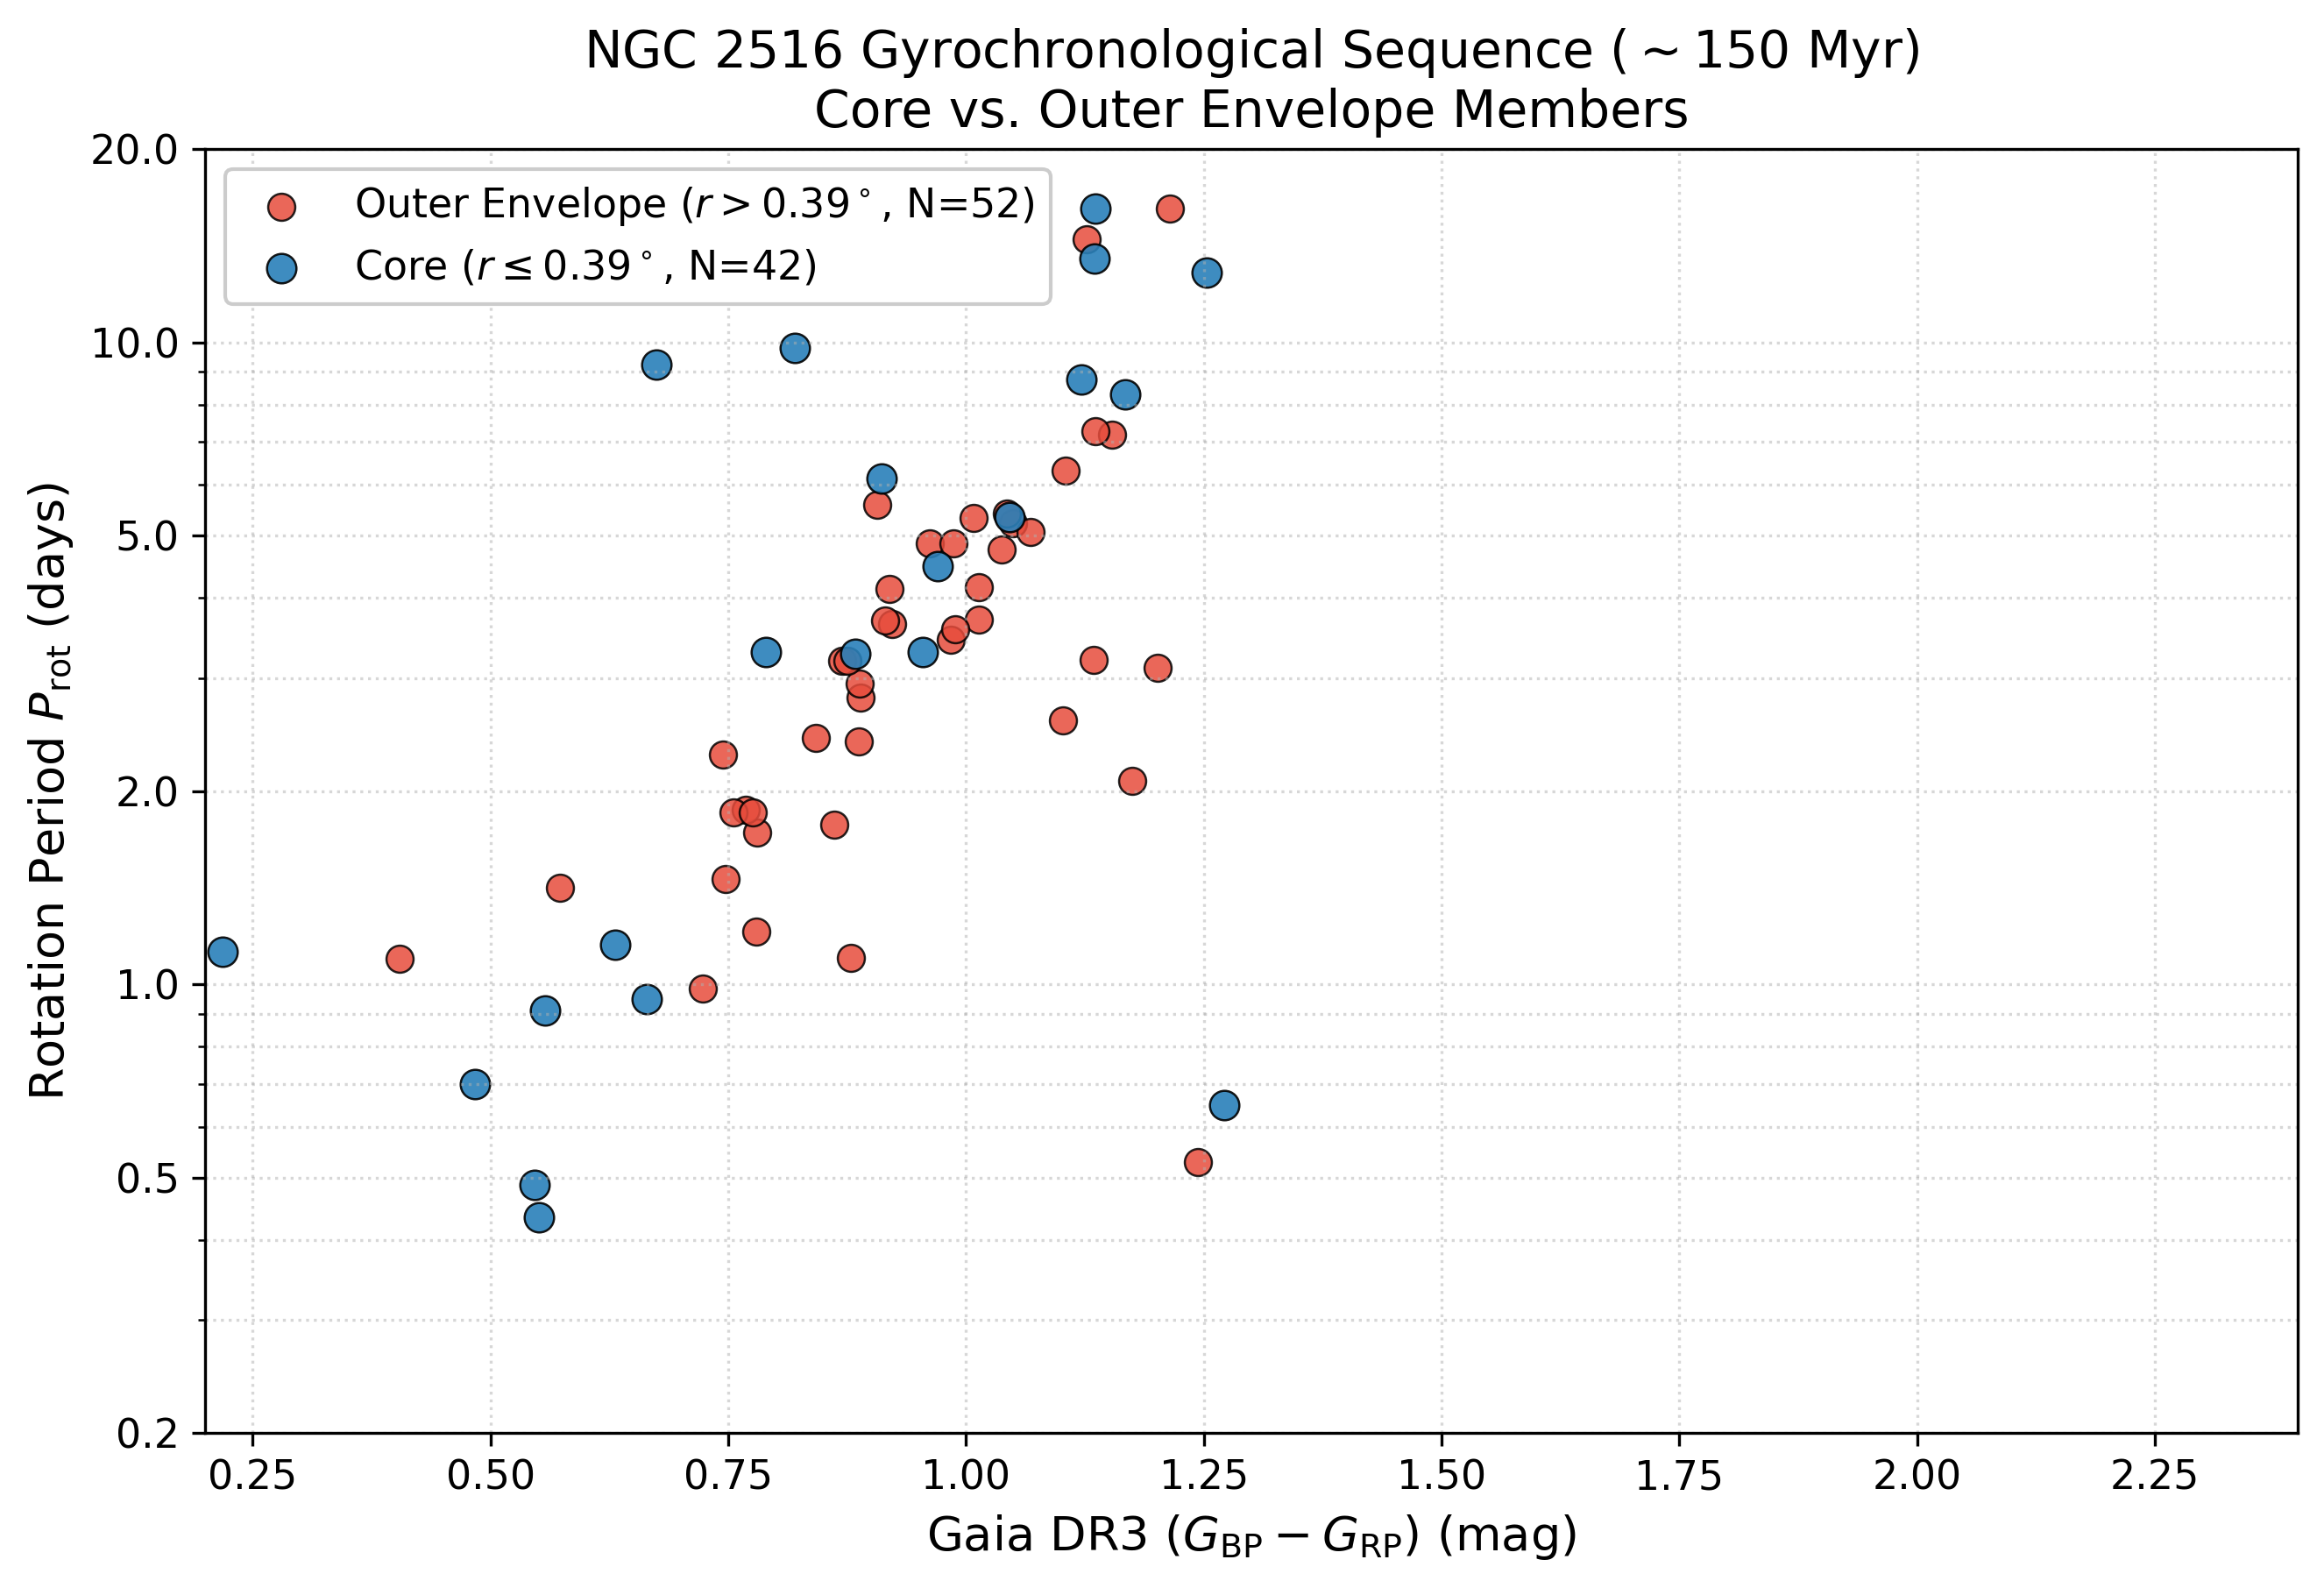

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

PROJECT_DIR = "/content/drive/MyDrive/NGC2516_Project"
ROT_CSV = os.path.join(PROJECT_DIR, "ngc2516_rotation_results.csv")
df_rot = pd.read_csv(ROT_CSV).drop_duplicates(subset=['source_id'])
reliable = df_rot[df_rot['is_reliable'] == True]

core = reliable[reliable['spatial_group'] == 'Core']
outer = reliable[reliable['spatial_group'] == 'Outer']

plt.close('all')  # Purge memory buffer to clear ghost text
fig, ax = plt.subplots(figsize=(9, 6.2), dpi=300)

ax.scatter(outer['bp_rp'], outer['prot_days'], c='#e74c3c', s=55, alpha=0.85,
           edgecolors='black', linewidth=0.6, label=f'Outer Envelope ($r > 0.39^\\circ$, N={len(outer)})')
ax.scatter(core['bp_rp'], core['prot_days'], c='#2980b9', s=65, alpha=0.9,
           edgecolors='black', linewidth=0.6, label=f'Core ($r \\leq 0.39^\\circ$, N={len(core)})')

ax.set_xlabel(r'Gaia DR3 $(G_{\rm BP} - G_{\rm RP})$ (mag)', fontsize=13)
ax.set_ylabel(r'Rotation Period $P_{\rm rot}$ (days)', fontsize=13)
ax.set_title(r'NGC 2516 Gyrochronological Sequence ($\sim 150$ Myr)' + '\n' + r'Core vs. Outer Envelope Members', fontsize=14)
ax.set_yscale('log')
ax.set_ylim(0.2, 20.0)
ax.set_xlim(0.2, 2.4)
ax.grid(True, which='both', ls=':', alpha=0.5)
ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=1.0, fontsize=11)
ax.set_yticks([0.2, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0])
ax.set_yticklabels(['0.2', '0.5', '1.0', '2.0', '5.0', '10.0', '20.0'])

plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, "Fig4_Gyrochronology_Core_vs_Outer_Clean.png"))
plt.savefig("Fig4_Gyrochronology_Core_vs_Outer_Clean.png")
plt.show()